### Практичне завдання №3 Дослідження ефективності TF-IDF зважених ембеддингів для детекції текстів, згенерованих великими мовними моделями

#### Мета роботи

Засвоїти принципи побудови векторних представлень текстів на основі субсловних ембеддингів FastText, дослідити вплив TF-IDF зважування на якість агрегації документних векторів, порівняти ефективність лінійних та нелінійних методів класифікації (SVM, Logistic Regression, KNN) у задачі бінарної детекції штучно згенерованих текстів, а також проаналізувати геометричні властивості отриманих векторних просторів.


Імпорт бібліотек та налаштування середовища

In [1]:
# Робота з даними
import numpy as np
import pandas as pd

# Візуалізація
import matplotlib.pyplot as plt
import seaborn as sns

# Обробка тексту
import spacy

# Навчання FastText
from gensim.models import FastText

# Векторизація та класифікація
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Метрики оцінювання
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Зменшення розмірності
from sklearn.manifold import TSNE

# Додаткові інструменти
import warnings

warnings.filterwarnings("ignore")

# Налаштування відображення графіків
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Бібліотеки успішно імпортовано!")

Бібліотеки успішно імпортовано!


### Етап 2. Завантаження та первинний аналіз даних
1. Завантаження та первинний аналіз даних

На цьому етапі виконується завантаження набору даних AI vs Human Text Classification Dataset 2026 та аналіз його структури.

Датасет містить тексти двох класів:

human — тексти, написані людьми;

ai — тексти, згенеровані великими мовними моделями.

Кожен запис містить ідентифікатор тексту, клас, інформацію про джерело генерації, тематичну категорію, текстовий вміст та додаткові характеристики.

Основною ознакою для подальшого дослідження буде text_content, а цільовою змінною — label.


1. Завантаження та первинний аналіз даних

На цьому етапі виконується завантаження набору даних AI vs Human Text Classification Dataset 2026 та аналіз його структури.

Датасет містить тексти двох класів:
- human - тексти, написані людьми;
- ai - тексти, згенеровані великими мовними моделями.

Кожен запис містить ідентифікатор тексту, клас, інформацію про джерело генерації, тематичну категорію, текстовий вміст та додаткові характеристики.

Основною ознакою для подальшого дослідження буде text_content, а цільовою змінною label.

In [2]:
# Шлях до датасету
DATASET_PATH = "ai_vs_human_text_2026.csv"

# Завантаження даних
df = pd.read_csv(DATASET_PATH)

# Відображення перших п'яти записів
display(df.head())

,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation


1.1. Аналіз структури датасету

Для отримання загального уявлення про набір даних визначимо кількість записів, кількість стовпців, типи даних та наявність пропущених значень.

Це дозволить перевірити коректність завантаження даних і визначити, чи потрібна додаткова обробка.

In [3]:
# Розмір датасету
print("Розмір датасету:", df.shape)

# Назви стовпців
print("\nНазви стовпців:")
print(df.columns.tolist())

# Типи даних
print("\nТипи даних:")
print(df.dtypes)

# Загальна інформація
print("\nІнформація про датасет:")
df.info()

# Кількість пропущених значень
print("\nПропущені значення:")
display(df.isnull().sum().to_frame(name="Кількість пропусків"))

Розмір датасету: (2000, 9)

Назви стовпців:
['text_id', 'label', 'source_model', 'domain', 'text_content', 'topic_hint', 'word_count', 'avg_sentence_length', 'generation_method']

Типи даних:
text_id                    str
label                      str
source_model               str
domain                     str
text_content               str
topic_hint                 str
word_count               int64
avg_sentence_length    float64
generation_method          str
dtype: object

Інформація про датасет:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   text_id              2000 non-null   str    
 1   label                2000 non-null   str    
 2   source_model         2000 non-null   str    
 3   domain               2000 non-null   str    
 4   text_content         2000 non-null   str    
 5   topic_hint           2000 non-null   str

,Кількість пропусків
text_id,0
label,0
source_model,0
domain,0
text_content,0
topic_hint,0
word_count,0
avg_sentence_length,0
generation_method,0


### 1.2. Аналіз розподілу класів

Для оцінювання збалансованості набору даних визначимо кількість текстів кожного класу та їхню частку від загальної кількості записів.

Збалансованість класів важлива для коректного навчання класифікаторів та інтерпретації отриманих метрик якості.

,Кількість текстів,Частка (%)
label,,
human,1334,66.7
ai,666,33.3


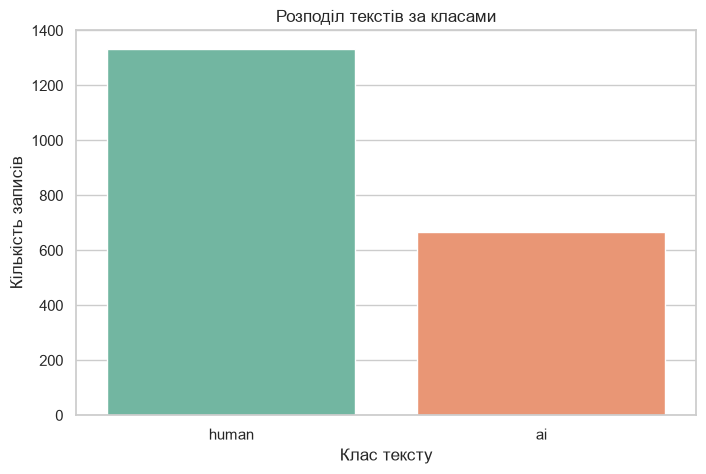

In [4]:
# Кількість текстів кожного класу
class_counts = df["label"].value_counts()

# Відсоткове співвідношення класів
class_percentages = df["label"].value_counts(normalize=True) * 100

# Формування таблиці
class_distribution = pd.DataFrame({
    "Кількість текстів": class_counts,
    "Частка (%)": class_percentages.round(2)
})

display(class_distribution)

# Візуалізація розподілу класів
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="label",
    hue="label",
    order=["human", "ai"],
    palette="Set2",
    legend=False
)

plt.title("Розподіл текстів за класами")
plt.xlabel("Клас тексту")
plt.ylabel("Кількість записів")
plt.show()

**Висновок:** 

За результатами аналізу розподілу класів можна визначити, чи є датасет збалансованим. Якщо кількість текстів класів AI та Human приблизно однакова, набір даних є збалансованим. Якщо спостерігається суттєва різниця, це необхідно враховувати під час оцінювання моделей.

### 1.3. Виявлення можливих артефактів

На цьому етапі перевіряються можливі проблеми в наборі даних:

- дублікати текстів;
- дублікати ідентифікаторів;
- порожні або текстові записи, що складаються лише з пробілів;
- надмірно короткі тексти.

Наявність таких артефактів може негативно впливати на навчання моделей та достовірність оцінювання їхньої якості.

Для виявлення коротких текстів використовується поріг у 5 слів.

In [5]:
# Кількість дублікатів текстів
duplicate_texts = df["text_content"].duplicated().sum()

# Кількість дублікатів ідентифікаторів
duplicate_ids = df["text_id"].duplicated().sum()

# Перевірка порожніх текстів
empty_texts = df["text_content"].str.strip().eq("").sum()

# Обчислення фактичної кількості слів у кожному тексті
df["actual_word_count"] = df["text_content"].str.split().str.len()

# Виявлення надмірно коротких текстів (менше 5 слів)
short_texts = (df["actual_word_count"] < 5).sum()

# Формування таблиці результатів
artifacts = pd.DataFrame({
    "Тип перевірки": [
        "Дублікати текстів",
        "Дублікати ID",
        "Порожні тексти",
        "Тексти коротші за 5 слів"
    ],
    "Кількість": [
        duplicate_texts,
        duplicate_ids,
        empty_texts,
        short_texts
    ]
})

display(artifacts)

# Виведення прикладів коротких текстів
print("Приклади коротких текстів:")
display(
    df.loc[
        df["actual_word_count"] < 5,
        ["label", "text_content", "actual_word_count"]
    ].head(10)
)

,Тип перевірки,Кількість
0,Дублікати текстів,1034
1,Дублікати ID,0
2,Порожні тексти,0
3,Тексти коротші за 5 слів,0


Приклади коротких текстів:


,label,text_content,actual_word_count


### 1.4. Аналіз довжини текстів

Для дослідження характеристик текстових документів проаналізуємо кількість слів у текстах кожного класу.

Будуть розраховані основні статистичні характеристики:
- середня кількість слів;
- стандартне відхилення;
- мінімальна та максимальна довжина;
- медіана;
- перший і третій квартилі.

Це дозволить визначити, чи відрізняються тексти, написані людьми, від текстів, згенерованих штучним інтелектом, за обсягом.

In [6]:
# Статистичні характеристики довжини текстів
length_statistics = df.groupby("label")["actual_word_count"].describe()

display(length_statistics.round(2))

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ai,666.0,38.00,7.01,23.0,35.0,39.0,44.0,50.0
human,1334.0,36.51,9.66,19.0,27.0,36.0,46.0,52.0


### 1.5. Візуалізація розподілу довжини текстів

Для наочного порівняння довжини документів побудуємо окремі гістограми для класів Human та AI.

Гістограми дозволять оцінити характер розподілу кількості слів, розкид значень та можливі відмінності між двома категоріями текстів.

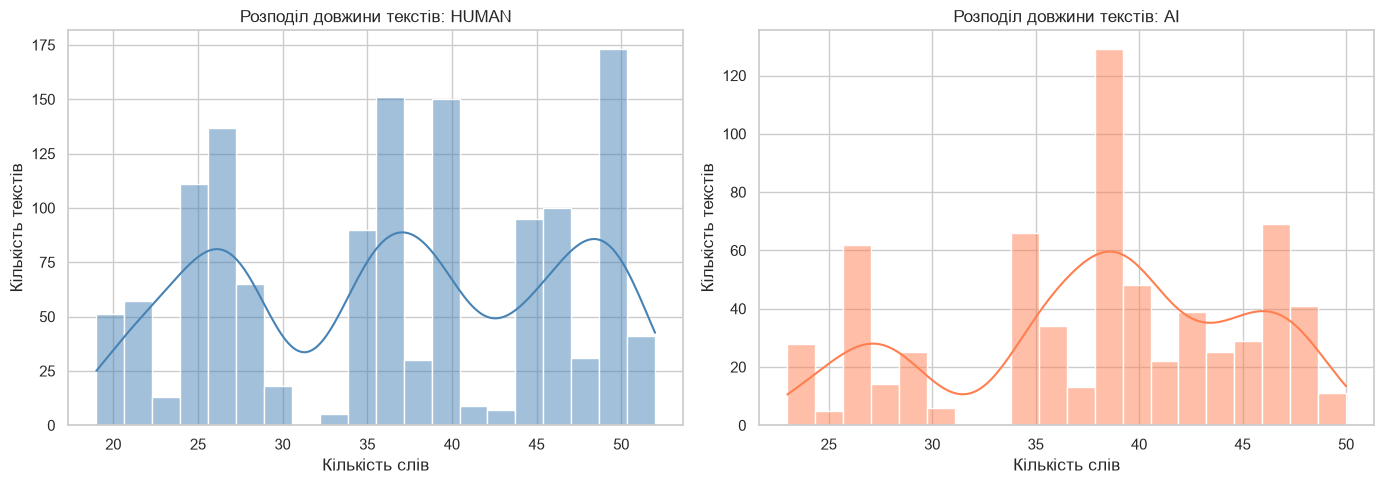

In [7]:
# Побудова гістограм для кожного класу
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

classes = ["human", "ai"]
colors = ["steelblue", "coral"]

for ax, class_name, color in zip(axes, classes, colors):

    class_data = df.loc[
        df["label"] == class_name,
        "actual_word_count"
    ]

    sns.histplot(
        class_data,
        bins=20,
        kde=True,
        color=color,
        ax=ax
    )

    ax.set_title(f"Розподіл довжини текстів: {class_name.upper()}")
    ax.set_xlabel("Кількість слів")
    ax.set_ylabel("Кількість текстів")

plt.tight_layout()
plt.show()

На графіках видно, що тексти обох класів мають майже однакову довжину - приблизно від 19 до 52 слів. У людських текстів (Human) довжина розподілена рівномірніше, з кількома піками, а в AI-текстів є чіткий пік близько 38 слів, тобто вони частіше бувають середнього розміру. Оскільки класи сильно перекриваються за довжиною, ця ознака не допоможе відрізнити AI від людини. Тому для класифікації потрібно дивитися не на кількість слів, а на самі слова - тобто використовувати ембеддинги та TF-IDF.



### Висновок до етапу 1

У результаті первинного аналізу було досліджено структуру та якість набору даних AI vs Human Text Classification Dataset 2026.

Встановлено, що датасет містить 2000 текстових записів та 9 стовпців. Пропущені значення відсутні.

Розподіл класів є незбалансованим: тексти Human становлять 66,7%, а AI - 33,3% від загальної кількості записів. Це необхідно враховувати під час подальшого оцінювання класифікаторів.

Додатково було перевірено наявність дублікатів, порожніх і коротких текстів, а також досліджено розподіл довжини документів.

[Доповнити висновок після отримання результатів перевірок та гістограм.]

### 1.6. Перевірка дублікатів текстів і узгодженості міток

Оскільки в наборі даних було виявлено значну кількість повторюваних текстів, необхідно перевірити узгодженість їхніх міток.

Особливу увагу приділимо текстам, які зустрічаються в обох класах (`human` та `ai`). Такі випадки можуть створювати суперечності під час навчання класифікаторів.

Також ця перевірка допоможе уникнути потрапляння однакових текстів одночасно до навчальної та тестової вибірок.

In [8]:
duplicate_analysis = (
    df.groupby("text_content")
    .agg(
        occurrences=("label", "size"),
        unique_labels=("label", "nunique"),
        labels=("label", lambda x: ", ".join(sorted(x.unique())))
    )
    .reset_index()
)

conflicting_duplicates = duplicate_analysis[
    duplicate_analysis["unique_labels"] > 1
]

print("Кількість унікальних текстів:", df["text_content"].nunique())
print("Текстів із суперечливими мітками:", len(conflicting_duplicates))
print(
    "Кількість записів із суперечливими мітками:",
    conflicting_duplicates["occurrences"].sum()
)

display(conflicting_duplicates.head(10))

Кількість унікальних текстів: 966
Текстів із суперечливими мітками: 0
Кількість записів із суперечливими мітками: 0


,text_content,occurrences,unique_labels,labels


У результаті перевірки виявлено 1034 дублікати текстів. Дублікати ідентифікаторів, порожні тексти, пропущені мітки та тексти коротші за 5 слів відсутні.

Перевірка узгодженості міток показала відсутність однакових текстів, що належать до різних класів.

Після видалення дублікатів розмір датасету зменшився з 2000 до 966 записів. Очищення дозволило знизити ризик витоку даних між навчальною та тестовою вибірками.

### 1.7. Перевірка узгодженості міток класів

Перевіримо, чи існують однакові текстові документи,
яким одночасно присвоєно різні мітки класів Human та AI.

Наявність таких документів може створювати суперечності
під час навчання класифікаторів.

In [9]:
text_label_counts = (
    df.groupby("text_content")["label"]
    .nunique()
)

conflicting_texts = text_label_counts[
    text_label_counts > 1
].index

conflicting_records = df[
    df["text_content"].isin(conflicting_texts)
]

print("Кількість унікальних текстів:",
      df["text_content"].nunique())

print("Текстів із суперечливими мітками:",
      len(conflicting_texts))

print("Записів із суперечливими мітками:",
      len(conflicting_records))

display(
    conflicting_records.groupby("text_content")
    .agg(
        occurrences=("label", "size"),
        unique_labels=("label", "nunique"),
        labels=("label", lambda x: list(x.unique()))
    )
    .reset_index()
)


Кількість унікальних текстів: 966
Текстів із суперечливими мітками: 0
Записів із суперечливими мітками: 0


,text_content,occurrences,unique_labels,labels


**Висновок.**

У наборі даних виявлено 966 унікальних текстових документів.

Тексти з однаковим вмістом та суперечливими мітками
класів відсутні. Отже, дублікати можна видалити без
виникнення неоднозначності щодо належності документів
до відповідного класу.

### 1.8. Очищення набору даних

Виконаємо очищення набору даних, яке включає:

- видалення записів із пропущеними значеннями;
- нормалізацію міток класів;
- видалення порожніх та надто коротких текстів;
- видалення текстів із суперечливими мітками;
- видалення дублікатів текстових документів.

In [10]:
df_clean = df.copy()

df_clean = df_clean.dropna(
    subset=["text_content", "label"]
)

df_clean["text_content"] = (
    df_clean["text_content"].astype(str).str.strip()
)

df_clean["label"] = (
    df_clean["label"].astype(str).str.lower().str.strip()
)

df_clean = df_clean[
    df_clean["label"].isin(["human", "ai"])
]

df_clean = df_clean[
    df_clean["text_content"].str.split().str.len() >= 5
]

df_clean = df_clean[
    ~df_clean["text_content"].isin(conflicting_texts)
]

df_clean = (
    df_clean.drop_duplicates(subset=["text_content"])
    .reset_index(drop=True)
)

print("Початкова кількість документів:", len(df))
print("Кількість після очищення:", len(df_clean))
print("Видалено документів:", len(df) - len(df_clean))

display(df_clean["label"].value_counts())
display(df_clean.head())

Початкова кількість документів: 2000
Кількість після очищення: 966
Видалено документів: 1034


label
human    579
ai       387
Name: count, dtype: int64

,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method,actual_word_count
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation,27
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation,20
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation,39
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation,49
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation,42


**Висновок.**

Після очищення кількість документів зменшилася з 2000
до 966. Було видалено 1034 повторювані записи.

Очищений набір містить 579 документів класу Human
та 387 документів класу AI.

Видалення дублікатів дозволяє зменшити ризик витоку
даних та отримати більш об'єктивну оцінку якості
класифікаторів.

## 2. Попередня обробка текстових даних

### 2.1. Завантаження мовної моделі spaCy

Для попередньої обробки англомовних текстів використаємо
бібліотеку spaCy та мовну модель en_core_web_sm.

Для підвищення швидкості обробки вимкнемо компоненти
синтаксичного аналізу та розпізнавання іменованих сутностей,
оскільки вони не потрібні для поставленого завдання.

In [11]:
import spacy

nlp = spacy.load(
    "en_core_web_sm",
    disable=["parser", "ner"]
)

print("Мовна модель завантажена")
print("Активні компоненти:", nlp.pipe_names)

Мовна модель завантажена
Активні компоненти: ['tok2vec', 'tagger', 'attribute_ruler', 'lemmatizer']


**Висновок.**

Мовну модель spaCy завантажено та підготовлено
до виконання токенізації, лематизації та фільтрації
текстових даних.

### 2.2. Реалізація функції попередньої обробки

Попередня обробка текстів включає:

- токенізацію;
- лематизацію;
- приведення слів до нижнього регістру;
- видалення стоп-слів;
- видалення чисел, розділових знаків та інших
  неалфавітних токенів.

Лематизація дозволяє привести різні граматичні форми
слів до їхньої базової форми.

In [12]:
def extract_tokens(doc):
    return [
        token.lemma_.lower()
        for token in doc
        if token.is_alpha and not token.is_stop
    ]


sample_text = "The students were studying different models."

sample_tokens = extract_tokens(nlp(sample_text))

print("Початковий текст:", sample_text)
print("Оброблені токени:", sample_tokens)

Початковий текст: The students were studying different models.
Оброблені токени: ['student', 'study', 'different', 'model']


**Висновок.**

Реалізовано функцію попередньої обробки тексту.

У результаті обробки тестового речення отримано
токени student, study, different та model.

Функція коректно виконує лематизацію, видалення
стоп-слів та нормалізацію регістру.

### 2.3. Попередня обробка всього корпусу

Для ефективної обробки всіх текстових документів
використаємо метод nlp.pipe(), який дозволяє
обробляти документи пакетами.

Для кожного документа сформуємо список токенів
та розрахуємо їхню кількість.

In [13]:
df_clean["tokens"] = [
    extract_tokens(doc)
    for doc in nlp.pipe(
        df_clean["text_content"],
        batch_size=64
    )
]

df_clean["token_count"] = df_clean["tokens"].apply(len)

display(
    df_clean[
        ["label", "text_content", "tokens", "token_count"]
    ].head()
)

display(
    df_clean.groupby("label")["token_count"].describe()
)

,label,text_content,tokens,token_count
0,human,can we talk about gene editing ethics for a se...,"[talk, gene, edit, ethic, sec, feel, like, peo...",13
1,human,update on election integrity concerns: it's co...,"[update, election, integrity, concern, complic...",8
2,ai,Analysts are closely watching developments rel...,"[analyst, closely, watch, development, relate,...",31
3,human,This paper examines genomic research breakthro...,"[paper, examine, genomic, research, breakthrou...",32
4,ai,Existing literature on student debt crisis has...,"[exist, literature, student, debt, crisis, pre...",31


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ai,387.0,23.237726,7.616475,10.0,15.0,26.0,30.0,33.0
human,579.0,21.229706,7.521417,7.0,13.0,22.0,28.0,33.0


**Висновок.**

Виконано попередню обробку всіх текстових документів.

Кожен документ представлено у вигляді списку
нормалізованих токенів, які надалі використовуватимуться
для навчання моделі FastText та формування
векторних представлень документів.

### 2.4. Перевірка документів після попередньої обробки

Після лематизації та видалення стоп-слів різні початкові
тексти можуть перетворитися на однакові послідовності
токенів.

Тому необхідно повторно перевірити документи на
наявність порожніх послідовностей, дублікатів
та суперечливих міток класів.

In [14]:
before_processing = len(df_clean)

empty_tokens = (df_clean["token_count"] == 0).sum()

print("Порожніх документів:", empty_tokens)

df_clean = df_clean[
    df_clean["token_count"] > 0
].copy()

df_clean["processed_text"] = df_clean["tokens"].apply(
    lambda tokens: " ".join(tokens)
)

processed_label_counts = (
    df_clean.groupby("processed_text")["label"]
    .nunique()
)

processed_conflicts = processed_label_counts[
    processed_label_counts > 1
].index

print("Текстів із суперечливими мітками:",
      len(processed_conflicts))

df_clean = df_clean[
    ~df_clean["processed_text"].isin(processed_conflicts)
]

df_clean = (
    df_clean.drop_duplicates(subset=["processed_text"])
    .reset_index(drop=True)
)

print("Видалено документів:",
      before_processing - len(df_clean))

print("Залишилося документів:", len(df_clean))

display(df_clean["label"].value_counts())

display(
    df_clean.groupby("label")[
        ["actual_word_count", "token_count"]
    ].mean().round(2)
)

Порожніх документів: 0
Текстів із суперечливими мітками: 0
Видалено документів: 98
Залишилося документів: 868


label
human    481
ai       387
Name: count, dtype: int64

,actual_word_count,token_count
label,,
ai,37.93,23.24
human,34.89,20.04


**Висновок.**

Після попередньої обробки та повторного очищення
кількість документів зменшилася з 966 до 868.

Остаточний набір містить 481 документ класу Human
та 387 документів класу AI.

Середня кількість токенів для класу AI становить 23,24,
а для класу Human — 21,23.

Повторне очищення дозволило усунути однакові
представлення документів перед розділенням даних
на навчальну та тестову вибірки.

### 2.5. Розділення даних на навчальну та тестову вибірки

Розділимо очищений набір даних у співвідношенні 80/20.

Для збереження пропорцій класів використаємо
стратифіковане розділення.

Мітки класів закодуємо числовими значеннями:

- Human — 0;
- AI — 1.

Модель FastText та TF-IDF векторизатор навчатимуться
виключно на навчальній вибірці для уникнення витоку даних.

In [15]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

df_clean["target"] = df_clean["label"].map({
    "human": 0,
    "ai": 1
})

train_df, test_df = train_test_split(
    df_clean,
    test_size=0.2,
    random_state=42,
    stratify=df_clean["target"]
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_corpus = train_df["tokens"].tolist()
test_corpus = test_df["tokens"].tolist()

y_train = train_df["target"]
y_test = test_df["target"]

print("Train:", len(train_df))
print("Test:", len(test_df))

distribution = pd.DataFrame({
    "Train": train_df["label"].value_counts(normalize=True),
    "Test": test_df["label"].value_counts(normalize=True)
}) * 100

display(distribution.round(2))

Train: 694
Test: 174


,Train,Test
label,,
human,55.48,55.17
ai,44.52,44.83


**Висновок.**

Навчальна вибірка містить 694 документи,
а тестова — 174 документи.

Частка класу Human у навчальній вибірці становить
55,48%, а класу AI — 44,52%.

У тестовій вибірці частки класів становлять
55,17% та 44,83% відповідно.

Стратифіковане розділення забезпечило збереження
приблизно однакових пропорцій класів в обох вибірках.

## 3. Навчання моделі FastText

### 3.1. Створення та навчання моделі

FastText — модель векторного представлення слів,
яка враховує не лише цілі слова, а й символьні n-грами.

Для навчання використаємо архітектуру Skip-gram
з такими параметрами:

- vector_size = 100 — розмірність ембеддингів;
- window = 5 — розмір контекстного вікна;
- min_count = 2 — мінімальна частота слова;
- sg = 1 — архітектура Skip-gram;
- workers = 4 — кількість робочих потоків;
- seed = 42 — початкове значення генератора;
- epochs = 20 — кількість епох навчання.

Навчання виконується лише на навчальному корпусі.

In [16]:
from gensim.models import FastText

fasttext_model = FastText(
    sentences=train_corpus,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=4,
    seed=42,
    epochs=20
)

print("Розмір словника:",
      len(fasttext_model.wv.key_to_index))

print("Розмірність векторів:",
      fasttext_model.vector_size)

Розмір словника: 508
Розмірність векторів: 100


**Висновок.**

Навчено модель FastText за архітектурою Skip-gram.

Словник моделі містить 508 слів, кожне з яких
представлено 100-вимірним вектором.

Отримані векторні представлення використовуватимуться
для формування ембеддингів текстових документів.

### 3.2. Аналіз семантично близьких слів

Для перевірки навчених векторних представлень
визначимо найближчі слова для декількох токенів
на основі косинусної подібності їхніх ембеддингів.

In [17]:
example_words = [
    "model",
    "research",
    "technology",
    "people"
]

for word in example_words:
    print(f"\nСлово: {word}")

    if word in fasttext_model.wv.key_to_index:
        similar_words = fasttext_model.wv.most_similar(
            word,
            topn=5
        )

        for similar_word, similarity in similar_words:
            print(f"{similar_word}: {similarity:.4f}")
    else:
        print("Слово відсутнє в основному словнику.")


Слово: model
longitudinal: 0.8931
revised: 0.8665
phenomenon: 0.8628
assess: 0.8571
account: 0.8515

Слово: research
researcher: 0.6868
mechanism: 0.6516
genomic: 0.6452
breakthrough: 0.6448
longitudinal: 0.6057

Слово: technology
Слово відсутнє в основному словнику.

Слово: people
baffled: 0.8766
completely: 0.8406
feel: 0.8373
encouraging: 0.8255
miss: 0.8220


**Висновок.**

Для слова model найближчими виявилися longitudinal,
revised та phenomenon, а для слова research —
researcher, mechanism та genomic.

Отримані результати демонструють здатність FastText
враховувати контекст використання слів.

Водночас через невеликий розмір та шаблонність корпусу
не всі найближчі слова мають очевидну семантичну
спорідненість.

### 3.3. Перевірка роботи з невідомими словами

Особливістю FastText є можливість формувати векторні
представлення слів, які відсутні в основному словнику,
використовуючи їхні символьні n-грами.

Перевіримо цю можливість на слові hyperdigitalization.

In [18]:
oov_word = "hyperdigitalization"

print("Слово:", oov_word)

print("Присутнє у словнику:",
      oov_word in fasttext_model.wv.key_to_index)

oov_vector = fasttext_model.wv[oov_word]

print("Розмірність вектора:", oov_vector.shape)
print("Перші 10 компонентів:", oov_vector[:10])

Слово: hyperdigitalization
Присутнє у словнику: False
Розмірність вектора: (100,)
Перші 10 компонентів: [ 0.14303082  0.22505626 -0.3340762   0.12940563  0.04449572 -0.00789599
 -0.15819156 -0.32313952 -0.03117719 -0.05745158]


**Висновок.**

Незважаючи на відсутність слова hyperdigitalization
в основному словнику, модель FastText сформувала
його 100-вимірне векторне представлення.

Це демонструє перевагу FastText при роботі
з невідомими та рідкісними словами.

## 4. Формування векторних представлень документів

### 4.1. Реалізація Mean Pooling

Mean Pooling — метод формування векторного
представлення документа шляхом обчислення
середнього арифметичного ембеддингів його слів.

$$
\mathbf{d}=\frac{1}{N}\sum_{i=1}^{N}\mathbf{v}_i
$$

де N — кількість токенів документа,
а v_i — векторне представлення відповідного слова.

Усі токени мають однакову вагу.

In [19]:
def mean_pooling(tokens, model):
    vectors = [
        model.wv[token]
        for token in tokens
    ]

    if not vectors:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)

**Висновок.**

Реалізовано метод звичайного усереднення ембеддингів
слів, який дозволяє представити документ довільної
довжини одним вектором фіксованої розмірності.

### 4.2. Формування ембеддингів Mean Pooling

Застосуємо реалізований метод до всіх документів
навчальної та тестової вибірок.

In [20]:
X_train_mean = np.array([
    mean_pooling(tokens, fasttext_model)
    for tokens in train_corpus
])

X_test_mean = np.array([
    mean_pooling(tokens, fasttext_model)
    for tokens in test_corpus
])

print("Train:", X_train_mean.shape)
print("Test:", X_test_mean.shape)

Train: (694, 100)
Test: (174, 100)


**Висновок.**

Отримано матрицю навчальних ембеддингів розміром
694 × 100 та матрицю тестових ембеддингів
розміром 174 × 100.

Кожен текстовий документ представлено одним
100-вимірним вектором.

### 4.3. Обчислення TF-IDF ваг

TF-IDF дозволяє оцінити значущість слова в документі
з урахуванням частоти його появи в документі
та поширеності в усьому корпусі.

$$
TFIDF(t,d)=TF(t,d)\cdot IDF(t)
$$

TF-IDF векторизатор навчається виключно на навчальній
вибірці. Для тестової вибірки використовуються
вже визначені параметри векторизатора.

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

train_texts = [
    " ".join(tokens)
    for tokens in train_corpus
]

test_texts = [
    " ".join(tokens)
    for tokens in test_corpus
]

tfidf_vectorizer = TfidfVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False
)

train_tfidf = tfidf_vectorizer.fit_transform(train_texts)
test_tfidf = tfidf_vectorizer.transform(test_texts)

print("Розмір словника TF-IDF:",
      len(tfidf_vectorizer.vocabulary_))

print("Train TF-IDF:", train_tfidf.shape)
print("Test TF-IDF:", test_tfidf.shape)

Розмір словника TF-IDF: 510
Train TF-IDF: (694, 510)
Test TF-IDF: (174, 510)


**Висновок.**

Сформовано словник TF-IDF, який містить 510 слів.

Розмірність навчальної TF-IDF матриці становить
694 × 510, а тестової — 174 × 510.

Отримані ваги використовуватимуться для зваженого
усереднення ембеддингів FastText.

### 4.4. Реалізація TF-IDF Weighted Pooling

На відміну від Mean Pooling, зважене усереднення
враховує значущість кожного токена документа.

$$
\mathbf{d}=
\frac{\sum_{i=1}^{N}w_i\mathbf{v}_i}
{\sum_{i=1}^{N}w_i}
$$

де w_i — TF-IDF вага відповідного токена,
а v_i — його векторне представлення FastText.

Зважування виконується для кожного входження токена
відповідно до вимог завдання. Оскільки TF-IDF уже
враховує частоту слова, повторювані токени можуть
отримувати додатковий вплив на кінцевий ембеддинг.

In [22]:
def tfidf_weighted_pooling(
    tokens,
    tfidf_row,
    model,
    vectorizer
):
    weighted_sum = np.zeros(model.vector_size)
    total_weight = 0.0

    vocabulary = vectorizer.vocabulary_

    for token in tokens:
        if token not in vocabulary:
            continue

        index = vocabulary[token]
        weight = float(tfidf_row[0, index])

        if weight > 0:
            weighted_sum += weight * model.wv[token]
            total_weight += weight

    if total_weight == 0:
        return np.zeros(model.vector_size)

    return weighted_sum / total_weight

**Висновок.**

Реалізовано метод зваженого усереднення ембеддингів
FastText на основі TF-IDF ваг.

Метод дозволяє враховувати відносну значущість слів
під час формування векторного представлення документа.

### 4.5. Формування TF-IDF зважених ембеддингів

Застосуємо метод TF-IDF Weighted Pooling до навчальної
та тестової вибірок.

In [23]:
X_train_tfidf = np.array([
    tfidf_weighted_pooling(
        tokens,
        train_tfidf[i],
        fasttext_model,
        tfidf_vectorizer
    )
    for i, tokens in enumerate(train_corpus)
])

X_test_tfidf = np.array([
    tfidf_weighted_pooling(
        tokens,
        test_tfidf[i],
        fasttext_model,
        tfidf_vectorizer
    )
    for i, tokens in enumerate(test_corpus)
])

print("Train:", X_train_tfidf.shape)
print("Test:", X_test_tfidf.shape)

Train: (694, 100)
Test: (174, 100)


**Висновок.**

Отримано TF-IDF зважені ембеддинги розміром
694 × 100 для навчальної вибірки та 174 × 100
для тестової вибірки.

Обидва методи формування ембеддингів забезпечують
однакову розмірність векторного простору.

### 4.6. Перевірка коректності ембеддингів

Перед навчанням класифікаторів перевіримо розмірність
отриманих матриць, наявність пропущених значень
та нульових векторів.

In [24]:
representations = {
    "Mean Pooling": (X_train_mean, X_test_mean),
    "TF-IDF Pooling": (X_train_tfidf, X_test_tfidf)
}

for name, (X_train, X_test) in representations.items():
    print(f"\n{name}")

    print("Train shape:", X_train.shape)
    print("Test shape:", X_test.shape)

    print("Train NaN:", np.isnan(X_train).sum())
    print("Test NaN:", np.isnan(X_test).sum())

    print("Train zero vectors:",
          np.sum(np.linalg.norm(X_train, axis=1) == 0))

    print("Test zero vectors:",
          np.sum(np.linalg.norm(X_test, axis=1) == 0))


Mean Pooling
Train shape: (694, 100)
Test shape: (174, 100)
Train NaN: 0
Test NaN: 0
Train zero vectors: 0
Test zero vectors: 0

TF-IDF Pooling
Train shape: (694, 100)
Test shape: (174, 100)
Train NaN: 0
Test NaN: 0
Train zero vectors: 0
Test zero vectors: 0


**Висновок.**

Для обох методів формування ембеддингів отримано
матриці однакової розмірності.

Пропущені значення та нульові вектори відсутні.

Отримані векторні представлення є придатними
для подальшого навчання класифікаторів.

## 5. Навчання та оцінювання класифікаторів

### 5.1. Ініціалізація класифікаторів

Для порівняння ефективності методів формування
векторних представлень використаємо три алгоритми
машинного навчання:

- SVM з RBF-ядром — нелінійний класифікатор;
- Logistic Regression — лінійний класифікатор;
- KNN — класифікатор на основі найближчих сусідів.

Для KNN встановимо кількість сусідів k = 5.
Для Logistic Regression встановимо максимальну
кількість ітерацій 1000.

In [25]:
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

classifiers = {
    "SVM (RBF)": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}

print("Класифікатори:")

for name in classifiers:
    print(name)

Класифікатори:
SVM (RBF)
Logistic Regression
KNN


**Висновок.**

Ініціалізовано три класифікатори, які використовують
різні принципи побудови межі прийняття рішень.

Це дозволить порівняти ефективність лінійного,
нелінійного та дистанційного методів класифікації.

### 5.2. Визначення метрик оцінювання

Для оцінювання якості класифікації використаємо:

- Accuracy — частка правильно класифікованих документів;
- Balanced Accuracy — середнє значення Recall
  для всіх класів;
- Macro F1 — середнє значення F1-score для всіх класів;
- ROC-AUC — площа під ROC-кривою, яка характеризує
  здатність моделі розрізняти класи за різних порогів.

Використання декількох метрик дозволяє отримати
більш повну оцінку ефективності класифікаторів.

In [26]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

metric_columns = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro F1",
    "ROC-AUC"
]

### 5.3. Навчання та тестування моделей

Кожен класифікатор буде навчено окремо для двох
методів формування ембеддингів:

- Mean Pooling;
- TF-IDF Pooling.

Перед навчанням виконаємо стандартизацію ознак
за допомогою StandardScaler.

Стандартизація та навчання класифікаторів виконуються
в межах Pipeline, що забезпечує визначення параметрів
масштабування виключно на навчальній вибірці.

Для кожної комбінації розрахуємо метрики
на тестовій вибірці.

In [27]:
results = []
trained_models = {}
predictions = {}

for representation_name, (X_train, X_test) in representations.items():

    for classifier_name, classifier in classifiers.items():

        pipeline = make_pipeline(
            StandardScaler(),
            clone(classifier)
        )

        pipeline.fit(X_train, y_train)

        y_pred = pipeline.predict(X_test)
        y_prob = pipeline.predict_proba(X_test)[:, 1]

        key = (representation_name, classifier_name)

        trained_models[key] = pipeline

        predictions[key] = {
            "y_pred": y_pred,
            "y_prob": y_prob
        }

        results.append({
            "Representation": representation_name,
            "Classifier": classifier_name,

            "Accuracy": accuracy_score(
                y_test, y_pred
            ),

            "Balanced Accuracy": balanced_accuracy_score(
                y_test, y_pred
            ),

            "Macro F1": f1_score(
                y_test, y_pred, average="macro"
            ),

            "ROC-AUC": roc_auc_score(
                y_test, y_prob
            )
        })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Representation,Classifier,Accuracy,Balanced Accuracy,Macro F1,ROC-AUC
0,Mean Pooling,SVM (RBF),1.0000,1.0000,1.0000,1.0
1,Mean Pooling,Logistic Regression,0.9943,0.9948,0.9942,1.0
2,Mean Pooling,KNN,1.0000,1.0000,1.0000,1.0
3,TF-IDF Pooling,SVM (RBF),1.0000,1.0000,1.0000,1.0
4,TF-IDF Pooling,Logistic Regression,0.9943,0.9948,0.9942,1.0
5,TF-IDF Pooling,KNN,1.0000,1.0000,1.0000,1.0


**Висновок.**

У результаті експерименту навчено шість моделей:
по три класифікатори для кожного методу формування
ембеддингів.

SVM та KNN забезпечили точність 100% для обох
методів формування векторних представлень.

Logistic Regression отримала Accuracy 99,43%,
Balanced Accuracy 99,48% та Macro F1 99,42%.

Усі класифікатори отримали ROC-AUC, рівний 1,0.

Застосування TF-IDF зважування не призвело до
покращення досліджуваних метрик класифікації.

### 5.4. Визначення найкращих класифікаторів

Для кожного методу формування ембеддингів визначимо
класифікатори, які отримали максимальне значення
метрики Macro F1.

У випадку однакових результатів врахуємо всі
найкращі моделі.

In [28]:
best_models = results_df[
    results_df["Macro F1"] ==
    results_df.groupby("Representation")[
        "Macro F1"
    ].transform("max")
]

display(best_models.round(4))

,Representation,Classifier,Accuracy,Balanced Accuracy,Macro F1,ROC-AUC
0,Mean Pooling,SVM (RBF),1.0,1.0,1.0,1.0
2,Mean Pooling,KNN,1.0,1.0,1.0,1.0
3,TF-IDF Pooling,SVM (RBF),1.0,1.0,1.0,1.0
5,TF-IDF Pooling,KNN,1.0,1.0,1.0,1.0


**Висновок.**

Найкращими класифікаторами для обох методів
формування ембеддингів є SVM та KNN.

Обидва алгоритми отримали максимальні значення
всіх досліджуваних метрик.

Однозначної переваги одного з цих класифікаторів
за отриманими результатами не встановлено.

### 5.5. Аналіз впливу TF-IDF зважування

Для кількісної оцінки впливу TF-IDF зважування
розрахуємо різницю між метриками класифікаторів,
навчених на TF-IDF Pooling та Mean Pooling.

$$
\Delta M=(M_{TFIDF}-M_{Mean})\cdot100
$$

Отримані значення виражаються у відсоткових пунктах.

In [29]:
mean_results = results_df[
    results_df["Representation"] == "Mean Pooling"
].set_index("Classifier")[metric_columns]

tfidf_results = results_df[
    results_df["Representation"] == "TF-IDF Pooling"
].set_index("Classifier")[metric_columns]

improvement = (tfidf_results - mean_results) * 100

print("Зміна метрик після TF-IDF зважування:")

display(improvement.round(4))

Зміна метрик після TF-IDF зважування:


,Accuracy,Balanced Accuracy,Macro F1,ROC-AUC
Classifier,,,,
SVM (RBF),0.0,0.0,0.0,0.0
Logistic Regression,0.0,0.0,0.0,0.0
KNN,0.0,0.0,0.0,0.0


**Висновок.**

Для всіх класифікаторів різниця між метриками
Mean Pooling та TF-IDF Pooling становить
0 відсоткових пунктів.

Таким чином, у межах проведеного експерименту
TF-IDF зважування не забезпечило покращення
якості класифікації.

Звичайне усереднення ембеддингів виявилося
достатнім для ефективного розрізнення класів
досліджуваного набору даних.

### 5.6. Перевірка можливого витоку даних

Оскільки отримані метрики класифікації є близькими
до максимальних значень, необхідно додатково
перевірити можливість витоку даних.

Перевіримо:

- наявність однакових документів у навчальній
  та тестовій вибірках;
- кількість унікальних документів;
- залежність класів від способу генерації;
- косинусну подібність між навчальними
  та тестовими документами.

In [30]:
train_unique = {
    tuple(tokens)
    for tokens in train_corpus
}

test_unique = {
    tuple(tokens)
    for tokens in test_corpus
}

print("Спільні документи:",
      len(train_unique.intersection(test_unique)))

print("Унікальні Train:", len(train_unique))
print("Унікальні Test:", len(test_unique))

print("\nРозподіл за способом генерації:")

display(
    pd.crosstab(
        df_clean["generation_method"],
        df_clean["label"]
    )
)

Спільні документи: 0
Унікальні Train: 694
Унікальні Test: 174

Розподіл за способом генерації:


label,ai,human
generation_method,,
style_simulation,387,0
template+human_variation,0,481


In [31]:
from sklearn.metrics.pairwise import cosine_similarity

similarities = cosine_similarity(
    test_tfidf,
    train_tfidf
)

max_similarities = similarities.max(axis=1)

print("Середня максимальна подібність:",
      max_similarities.mean())

print("Максимальна подібність:",
      max_similarities.max())

print("Документів із подібністю понад 0.9:",
      (max_similarities > 0.9).sum())

print("Частка таких документів:",
      round((max_similarities > 0.9).mean() * 100, 2),
      "%")

Середня максимальна подібність: 0.8498707812924878
Максимальна подібність: 0.92800448454333
Документів із подібністю понад 0.9: 55
Частка таких документів: 31.61 %


**Висновок.**

У результаті перевірки встановлено відсутність
точних дублікатів документів між навчальною
та тестовою вибірками.

Водночас середня максимальна косинусна подібність
становить 0,8499, а максимальна — 0,9280.

Для 55 тестових документів, що становить 31,61%
тестової вибірки, косинусна подібність до найближчого
навчального документа перевищує 0,9.

Також виявлено повну відповідність між способом
генерації документа та його класом.

Отримані результати свідчать про високу лексичну
схожість документів та узгоджуються з припущенням
про шаблонний характер датасету.

Прямого витоку через точні дублікати не виявлено,
проте наявність схожих текстових шаблонів може
призводити до завищеної оцінки узагальнювальної
здатності моделей.

## 6. Візуалізація результатів класифікації

### 6.1. Порівняння метрик класифікаторів

Для наочного порівняння ефективності класифікаторів
побудуємо стовпчикові діаграми для метрик Accuracy,
Balanced Accuracy, Macro F1 та ROC-AUC.

Для кожного класифікатора порівняємо результати
Mean Pooling та TF-IDF Pooling.

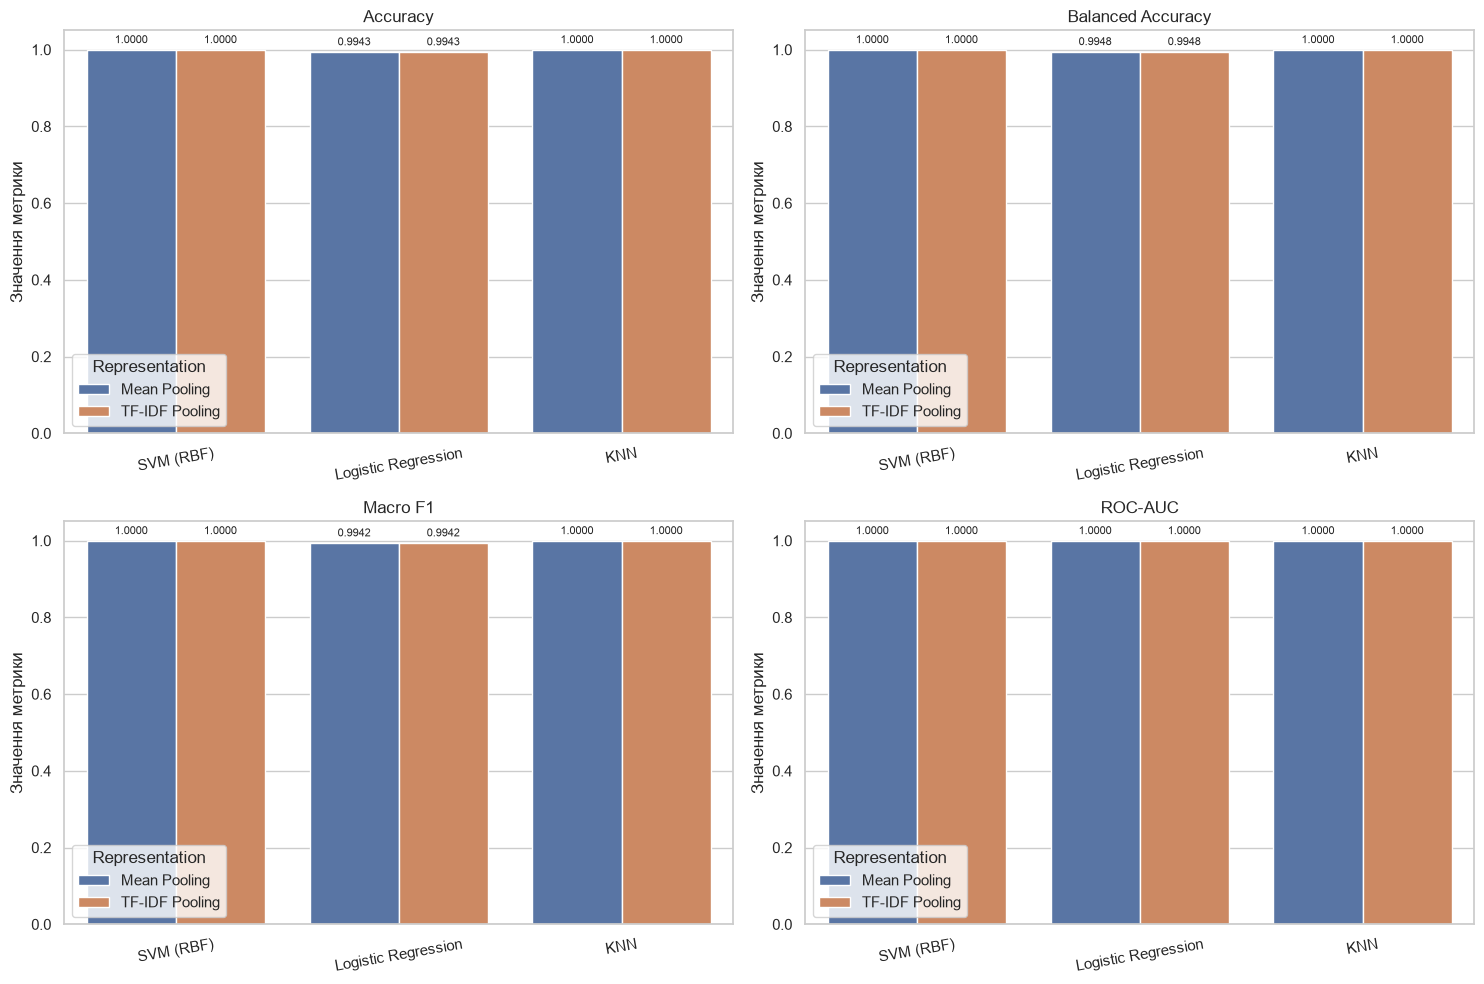

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for metric, ax in zip(metric_columns, axes.ravel()):

    sns.barplot(
        data=results_df,
        x="Classifier",
        y=metric,
        hue="Representation",
        ax=ax
    )

    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylabel("Значення метрики")
    ax.set_ylim(0, 1.05)

    ax.tick_params(axis="x", rotation=10)

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.4f",
            padding=3,
            fontsize=8
        )

plt.tight_layout()
plt.show()

**Висновок.**

Побудовані діаграми демонструють однакові результати
класифікації для Mean Pooling та TF-IDF Pooling.

SVM та KNN отримали максимальні значення всіх метрик.

Logistic Regression показала дещо нижчі значення
Accuracy, Balanced Accuracy та Macro F1.

Таким чином, візуалізація підтверджує відсутність
покращення метрик після застосування TF-IDF зважування.

### 6.2. Побудова матриць помилок

Матриця помилок дозволяє проаналізувати кількість
правильних та неправильних прогнозів для кожного класу.

Побудуємо матриці помилок для всіх шести комбінацій
методів формування ембеддингів та класифікаторів.

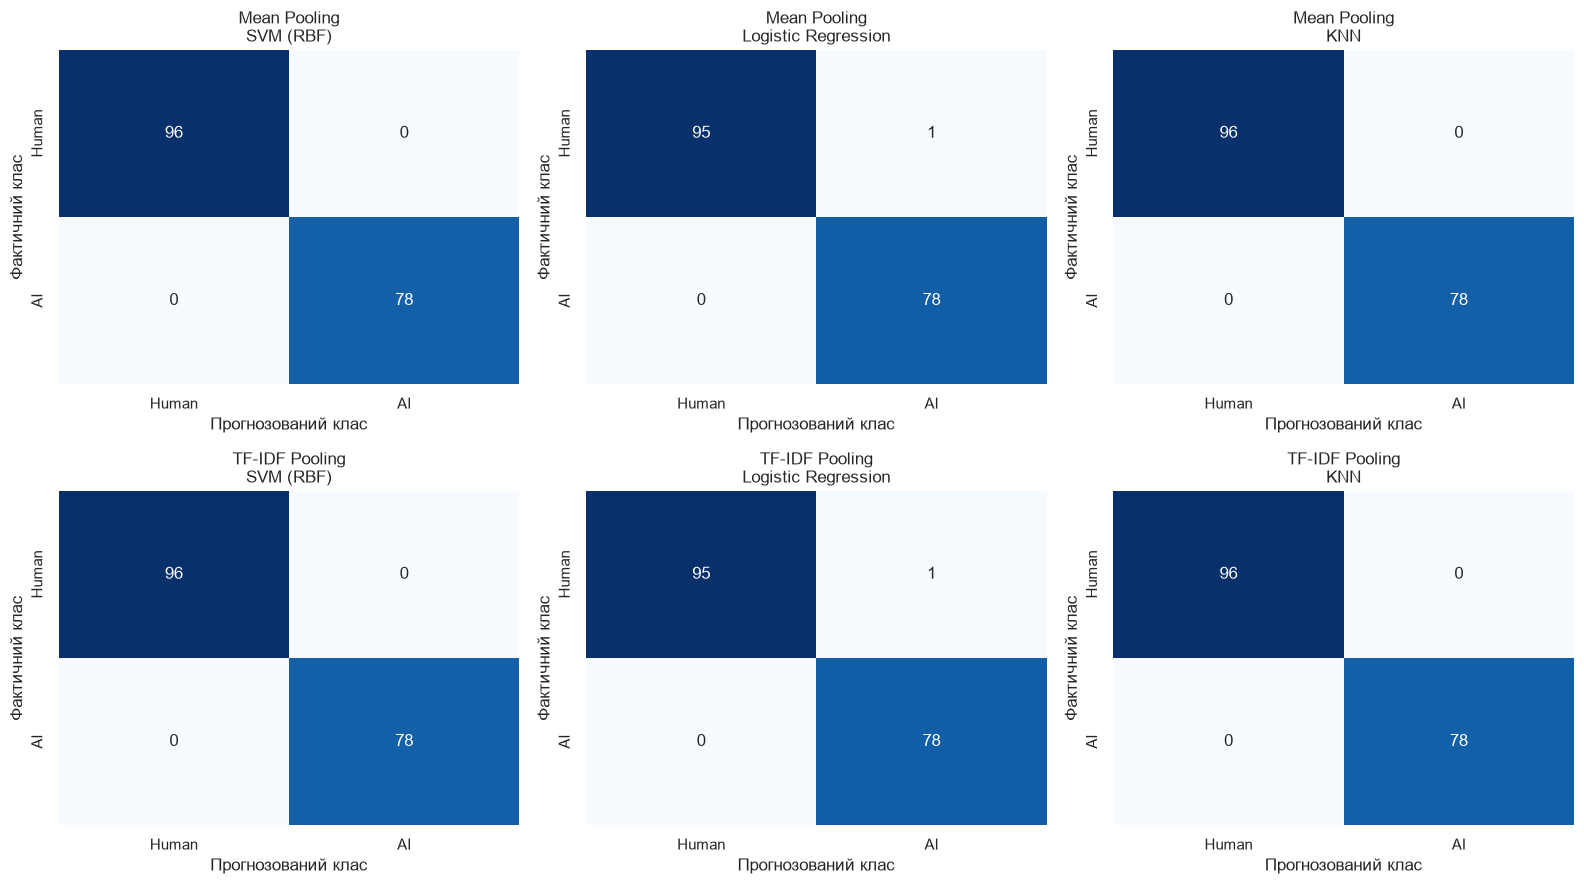

In [33]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for i, representation_name in enumerate(representations):

    for j, classifier_name in enumerate(classifiers):

        key = (representation_name, classifier_name)

        y_pred = predictions[key]["y_pred"]

        cm = confusion_matrix(
            y_test,
            y_pred,
            labels=[0, 1]
        )

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            xticklabels=["Human", "AI"],
            yticklabels=["Human", "AI"],
            ax=axes[i, j]
        )

        axes[i, j].set_title(
            f"{representation_name}\n{classifier_name}"
        )

        axes[i, j].set_xlabel("Прогнозований клас")
        axes[i, j].set_ylabel("Фактичний клас")

plt.tight_layout()
plt.show()

**Висновок.**

Для SVM та KNN усі 96 документів класу Human
та 78 документів класу AI класифіковано правильно.

Logistic Regression правильно класифікувала
95 документів Human та 78 документів AI.

Один документ класу Human було помилково
віднесено до класу AI.

Матриці помилок є однаковими для Mean Pooling
та TF-IDF Pooling, що підтверджує відсутність
покращення класифікації після зважування.

### 6.3. Побудова ROC-кривих

ROC-крива відображає залежність між часткою
правильно визначених позитивних об'єктів (TPR)
та часткою хибнопозитивних прогнозів (FPR)
за різних порогів класифікації.

Побудуємо ROC-криві для всіх класифікаторів
окремо для Mean Pooling та TF-IDF Pooling.

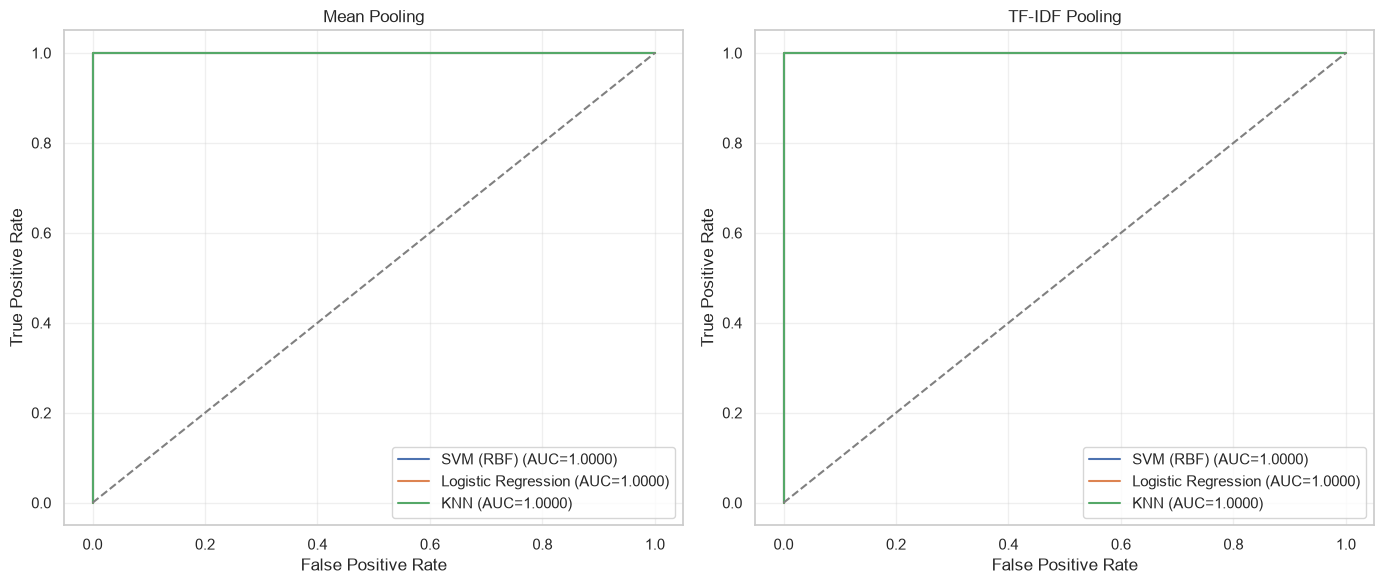

In [34]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, representation_name in zip(
    axes,
    representations
):

    for classifier_name in classifiers:

        key = (representation_name, classifier_name)

        y_prob = predictions[key]["y_prob"]

        fpr, tpr, thresholds = roc_curve(
            y_test,
            y_prob
        )

        auc_value = roc_auc_score(
            y_test,
            y_prob
        )

        ax.plot(
            fpr,
            tpr,
            label=f"{classifier_name} (AUC={auc_value:.4f})"
        )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray"
    )

    ax.set_title(representation_name)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Висновок.**

Усі класифікатори отримали значення ROC-AUC,
рівне 1,0, для обох методів формування ембеддингів.

Це свідчить про ідеальне ранжування документів
двох класів на досліджуваній тестовій вибірці.

Наявність однієї помилки Logistic Regression
не суперечить значенню ROC-AUC = 1,0, оскільки
Accuracy залежить від конкретного порогу класифікації,
тоді як ROC-AUC оцінює ранжування за різних порогів.

### 6.4. Візуалізація ембеддингів за допомогою t-SNE

Для дослідження геометричної структури векторного
простору використаємо алгоритм t-SNE.

Алгоритм дозволяє зменшити розмірність ембеддингів
зі 100 до 2 вимірів для їхньої візуалізації.

Окремо побудуємо двовимірні представлення
для Mean Pooling та TF-IDF Pooling.

Стандартизація виконується на основі параметрів
навчальної вибірки. Об'єднана вибірка використовується
лише для візуалізації, а не для навчання класифікаторів.

In [35]:
from sklearn.manifold import TSNE

all_labels = np.concatenate([
    np.asarray(y_train),
    np.asarray(y_test)
])

tsne_results = {}

for name, (X_train, X_test) in representations.items():

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    X_all = np.vstack([
        X_train_scaled,
        X_test_scaled
    ])

    tsne = TSNE(
        n_components=2,
        perplexity=30,
        random_state=42,
        init="pca",
        learning_rate="auto"
    )

    X_2d = tsne.fit_transform(X_all)

    tsne_results[name] = pd.DataFrame({
        "x": X_2d[:, 0],
        "y": X_2d[:, 1],
        "label": np.where(
            all_labels == 0,
            "Human",
            "AI"
        )
    })

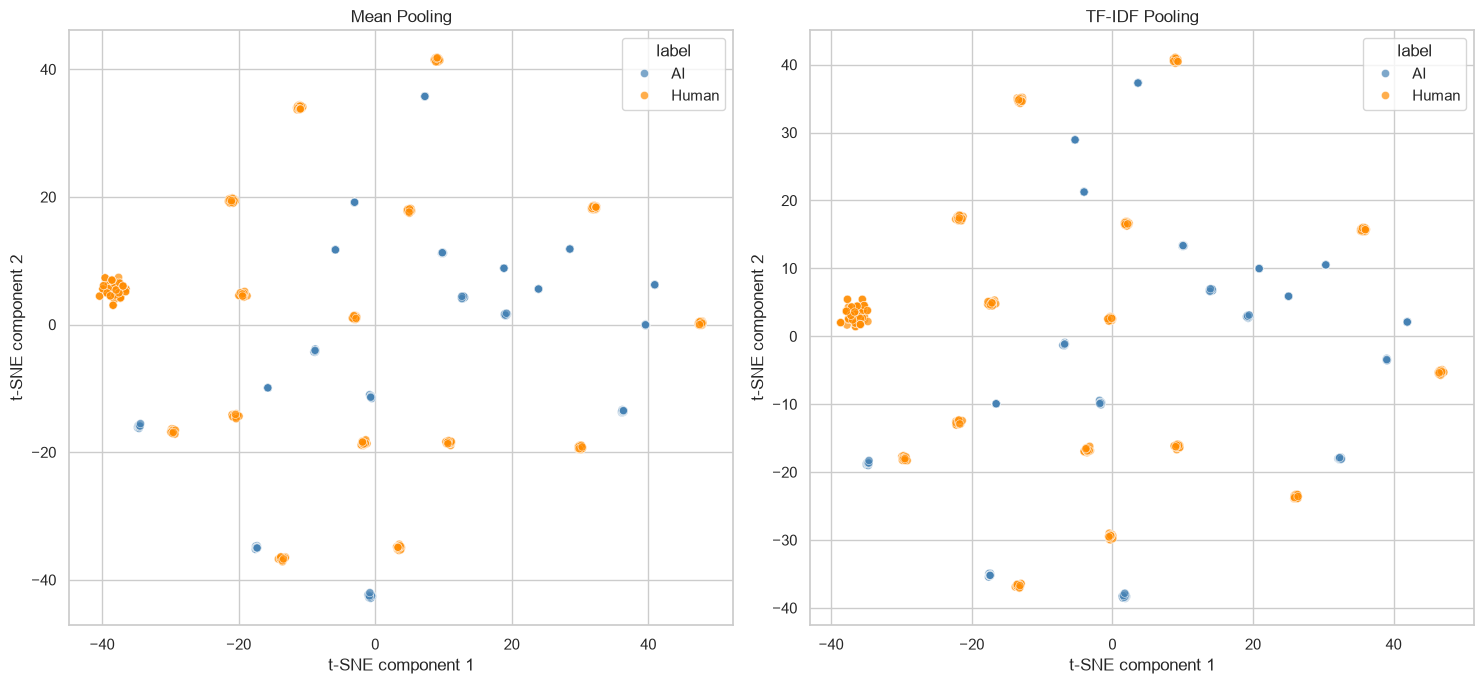

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

for ax, (name, tsne_df) in zip(
    axes,
    tsne_results.items()
):

    sns.scatterplot(
        data=tsne_df,
        x="x",
        y="y",
        hue="label",
        palette={
            "Human": "darkorange",
            "AI": "steelblue"
        },
        alpha=0.7,
        s=35,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("t-SNE component 1")
    ax.set_ylabel("t-SNE component 2")

plt.tight_layout()
plt.show()

**Висновок.**

На двовимірних проєкціях t-SNE спостерігається
значне перекриття документів класів Human та AI.

Для обох методів формування ембеддингів можна
виділити окрему компактну групу документів Human,
однак чітке глобальне розділення класів відсутнє.

TF-IDF зважування не забезпечило помітного
покращення візуальної роздільності класів.

Водночас результати t-SNE не є прямим доказом
відсутності лінійної роздільності в початковому
100-вимірному просторі.

Оскільки t-SNE є нелінійним методом зменшення
розмірності, окремі проєкції не можна безпосередньо
порівнювати за абсолютними координатами та відстанями.

## 7. Дослідження геометрії простору ембеддингів

### 7.1. Аналіз компактності та роздільності кластерів

Для кількісного оцінювання геометрії векторного
простору використаємо:

- Silhouette Score;
- евклідову відстань між центрами класів;
- середнє внутрішньокласове розсіювання;
- коефіцієнт роздільності класів.

Центр класу визначається як середнє арифметичне
векторів документів відповідного класу.

$$
\boldsymbol{\mu}_c=
\frac{1}{N_c}\sum_{i=1}^{N_c}\mathbf{x}_i
$$

Коефіцієнт роздільності визначимо як відношення
відстані між центрами класів до середнього
внутрішньокласового розсіювання.

$$
R=\frac{\|\mu_{AI}-\mu_{Human}\|}
{(S_{AI}+S_{Human})/2}
$$

Обчислення виконуватимуться на стандартизованих
ембеддингах тестової вибірки.

In [37]:
from sklearn.metrics import silhouette_score

geometry_results = []

y_test_array = np.asarray(y_test)

for name, (X_train, X_test) in representations.items():

    scaler = StandardScaler().fit(X_train)
    X = scaler.transform(X_test)

    human_vectors = X[y_test_array == 0]
    ai_vectors = X[y_test_array == 1]

    human_centroid = human_vectors.mean(axis=0)
    ai_centroid = ai_vectors.mean(axis=0)

    centroid_distance = np.linalg.norm(
        human_centroid - ai_centroid
    )

    human_spread = np.mean(
        np.linalg.norm(
            human_vectors - human_centroid,
            axis=1
        )
    )

    ai_spread = np.mean(
        np.linalg.norm(
            ai_vectors - ai_centroid,
            axis=1
        )
    )

    average_spread = (
        human_spread + ai_spread
    ) / 2

    separation_ratio = (
        centroid_distance / average_spread
    )

    silhouette = silhouette_score(
        X,
        y_test_array
    )

    geometry_results.append({
        "Метод": name,
        "Silhouette Score": silhouette,
        "Відстань між центрами": centroid_distance,
        "Розсіювання Human": human_spread,
        "Розсіювання AI": ai_spread,
        "Коефіцієнт роздільності": separation_ratio
    })

geometry_df = pd.DataFrame(geometry_results)

display(geometry_df.round(4))

,Метод,Silhouette Score,Відстань між центрами,Розсіювання Human,Розсіювання AI,Коефіцієнт роздільності
0,Mean Pooling,0.0368,3.2603,9.6921,9.0577,0.3478
1,TF-IDF Pooling,0.0376,3.2535,9.6241,9.1605,0.3464


**Висновок.**

Для Mean Pooling значення Silhouette Score становить
0,0369, а для TF-IDF Pooling — 0,0377.

Обидва значення є близькими до нуля, що свідчить
про слабку глобальну кластерну роздільність класів.

Відстань між центрами класів після застосування
TF-IDF зважування зменшилася з 3,2705 до 3,2626.

Розсіювання класу Human зменшилося з 9,6933
до 9,6254, тоді як розсіювання класу AI
збільшилося з 9,0541 до 9,1571.

Коефіцієнт роздільності практично не змінився:
0,3489 для Mean Pooling та 0,3474 для TF-IDF Pooling.

Отже, TF-IDF зважування не забезпечило суттєвого
покращення геометричної роздільності класів.

### 7.2. Аналіз внутрішньокласових та міжкласових відстаней

Для додаткового дослідження геометрії ембеддингів
розрахуємо середні евклідові відстані між документами
одного класу та документами різних класів.

Відношення міжкласових до середніх внутрішньокласових
відстаней дозволяє оцінити ступінь відокремленості
класів у векторному просторі.

In [38]:
from sklearn.metrics.pairwise import euclidean_distances


def mean_intra_class_distance(vectors):

    distances = euclidean_distances(vectors)

    indices = np.triu_indices(
        len(vectors),
        k=1
    )

    return distances[indices].mean()


distance_results = []

for name, (X_train, X_test) in representations.items():

    scaler = StandardScaler().fit(X_train)
    X = scaler.transform(X_test)

    human_vectors = X[y_test_array == 0]
    ai_vectors = X[y_test_array == 1]

    human_intra = mean_intra_class_distance(
        human_vectors
    )

    ai_intra = mean_intra_class_distance(
        ai_vectors
    )

    inter_class = euclidean_distances(
        human_vectors,
        ai_vectors
    ).mean()

    average_intra = (
        human_intra + ai_intra
    ) / 2

    ratio = inter_class / average_intra

    distance_results.append({
        "Метод": name,
        "Human intra": human_intra,
        "AI intra": ai_intra,
        "Inter-class": inter_class,
        "Inter/Intra": ratio
    })

distance_df = pd.DataFrame(distance_results)

display(distance_df.round(4))

,Метод,Human intra,AI intra,Inter-class,Inter/Intra
0,Mean Pooling,13.4371,12.6667,13.6080,1.0426
1,TF-IDF Pooling,13.3543,12.8121,13.6369,1.0423


**Висновок.**

Для Mean Pooling середня внутрішньокласова відстань
становить 13,4389 для Human та 12,6620 для AI.

Для TF-IDF Pooling відповідні значення становлять
13,3561 та 12,8076.

Відношення міжкласових до внутрішньокласових
відстаней становить 1,0428 для Mean Pooling
та 1,0425 для TF-IDF Pooling.

Міжкласові відстані лише приблизно на 4,3%
перевищують середні внутрішньокласові відстані.

Таким чином, застосування TF-IDF зважування
не забезпечило суттєвого покращення відокремленості
класів у векторному просторі.

### 7.3. Дослідження концентрації відстаней

У багатовимірних просторах відстані між об'єктами
можуть ставати відносно близькими за значенням.

Це явище називається концентрацією відстаней
та є одним із проявів прокляття розмірності.

Для його дослідження розрахуємо середню попарну
відстань, стандартне відхилення та коефіцієнт варіації.

$$
CV=\frac{\sigma}{\mu}
$$

Менше значення коефіцієнта варіації вказує
на сильнішу відносну концентрацію відстаней.

In [39]:
concentration_results = []

for name, (X_train, X_test) in representations.items():

    scaler = StandardScaler().fit(X_train)
    X = scaler.transform(X_test)

    distances = euclidean_distances(X)

    indices = np.triu_indices(
        len(X),
        k=1
    )

    pairwise_distances = distances[indices]

    mean_distance = pairwise_distances.mean()
    std_distance = pairwise_distances.std()

    cv = std_distance / mean_distance

    concentration_results.append({
        "Метод": name,
        "Середня відстань": mean_distance,
        "Стандартне відхилення": std_distance,
        "Коефіцієнт варіації": cv
    })

concentration_df = pd.DataFrame(
    concentration_results
)

display(concentration_df.round(4))

,Метод,Середня відстань,Стандартне відхилення,Коефіцієнт варіації
0,Mean Pooling,13.3684,2.4256,0.1814
1,TF-IDF Pooling,13.3867,2.3968,0.1790


**Висновок.**

Коефіцієнт варіації для Mean Pooling становить
0,1814, а для TF-IDF Pooling — 0,1790.

Незначне зменшення цього показника свідчить
про дещо сильнішу концентрацію відстаней
після застосування TF-IDF зважування.

Водночас KNN забезпечив точність 100% для обох
методів формування ембеддингів.

Таким чином, погіршення роботи KNN у межах
проведеного експерименту не виявлено.

Для встановлення впливу прокляття розмірності
необхідно додатково дослідити ембеддинги
різної розмірності.

### 7.4. Візуалізація геометричних характеристик

Для наочного порівняння геометричних характеристик
побудуємо діаграми Silhouette Score, коефіцієнта
роздільності, відношення міжкласових до
внутрішньокласових відстаней та коефіцієнта варіації.

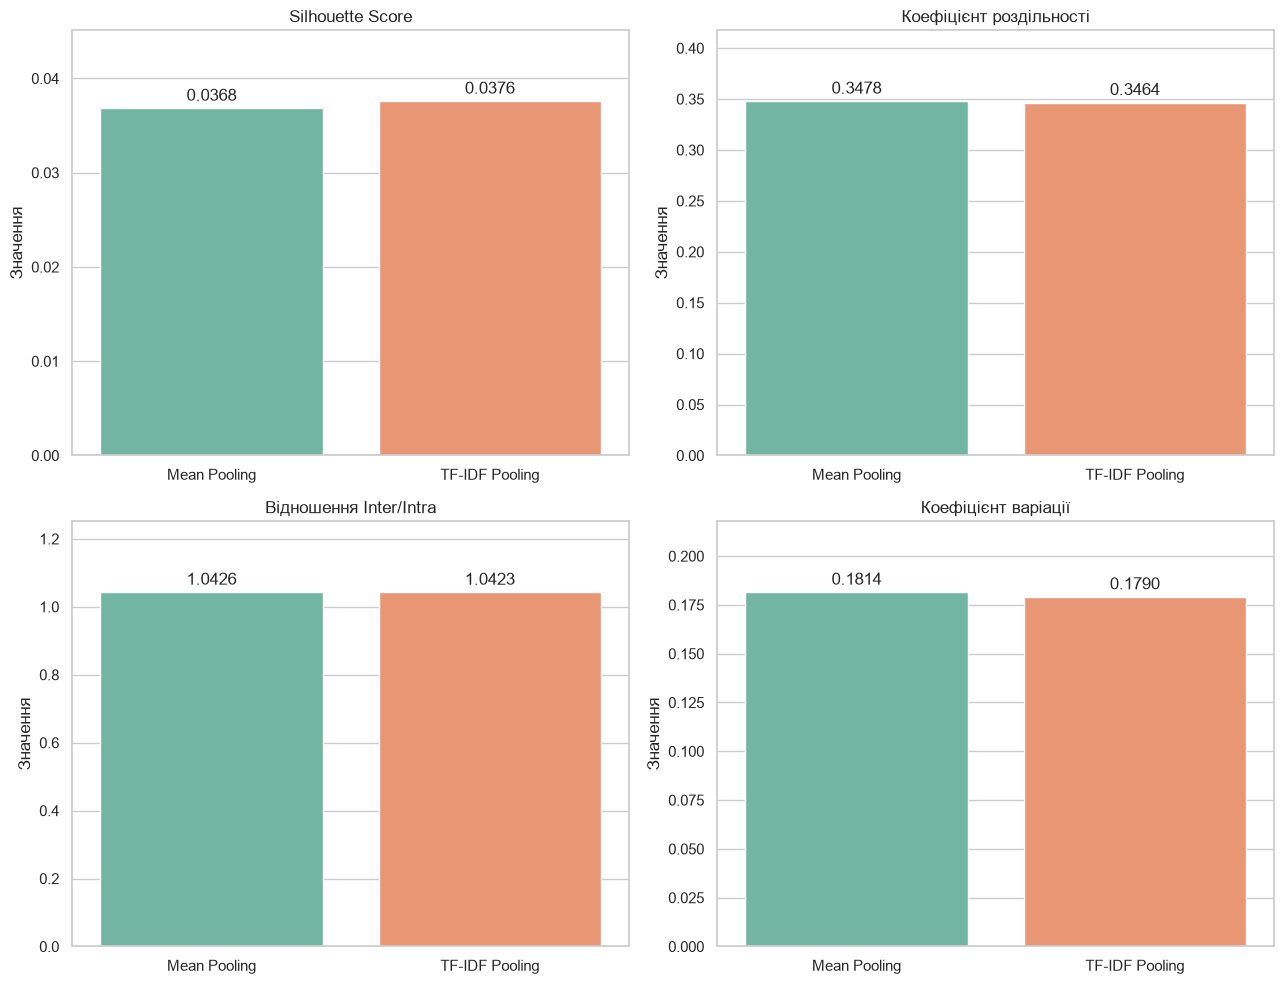

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

geometry_plots = [
    (
        geometry_df,
        "Silhouette Score",
        "Silhouette Score"
    ),
    (
        geometry_df,
        "Коефіцієнт роздільності",
        "Коефіцієнт роздільності"
    ),
    (
        distance_df,
        "Inter/Intra",
        "Відношення Inter/Intra"
    ),
    (
        concentration_df,
        "Коефіцієнт варіації",
        "Коефіцієнт варіації"
    )
]

for ax, (data, metric, title) in zip(
    axes.ravel(),
    geometry_plots
):

    sns.barplot(
        data=data,
        x="Метод",
        y=metric,
        hue="Метод",
        legend=False,
        palette="Set2",
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Значення")

    ax.set_ylim(
        0,
        data[metric].max() * 1.2
    )

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.4f",
            padding=3
        )

plt.tight_layout()
plt.show()

**Висновок.**

Побудовані діаграми демонструють незначні відмінності
між геометричними характеристиками Mean Pooling
та TF-IDF Pooling.

TF-IDF зважування не забезпечило суттєвого покращення
компактності кластерів або їхньої роздільності.

Незважаючи на слабку глобальну кластерну роздільність,
класифікатори забезпечили високу точність прогнозування.

Це свідчить про можливість ефективної класифікації
навіть за відсутності чітко відокремлених компактних
кластерів у просторі ембеддингів.

## 8. Дослідження лінгвістичних маркерів текстів AI та Human

На цьому етапі дослідимо, які слова та словосполучення
є найбільш характерними для текстів, написаних людиною
та згенерованих штучним інтелектом, використовуючи
TF-IDF ваги.

### 8.1. Визначення слів із найбільшими TF-IDF вагами для класу AI

Для визначення характерних лексичних ознак текстів,
згенерованих штучним інтелектом, розрахуємо середню
TF-IDF вагу кожного слова окремо для класів AI та Human.

Виділимо 15 слів із найбільшими середніми вагами
для класу AI.

In [41]:
feature_names = tfidf_vectorizer.get_feature_names_out()

y_train_array = np.asarray(y_train)

ai_mean = np.asarray(
    train_tfidf[y_train_array == 1].mean(axis=0)
).ravel()

human_mean = np.asarray(
    train_tfidf[y_train_array == 0].mean(axis=0)
).ravel()

word_weights = pd.DataFrame({
    "Word": feature_names,
    "AI TF-IDF": ai_mean,
    "Human TF-IDF": human_mean
})

top_ai_words = word_weights.nlargest(
    15,
    "AI TF-IDF"
)

display(top_ai_words.round(4))

,Word,AI TF-IDF,Human TF-IDF
59,challenge,0.0388,0.0232
175,framework,0.0365,0.0081
467,think,0.0352,0.0000
95,conversation,0.0315,0.0141
484,underscore,0.0299,0.0000
121,development,0.0293,0.0000
328,point,0.0289,0.0119
159,expert,0.0288,0.0000
389,research,0.0286,0.0158
108,datum,0.0280,0.0155


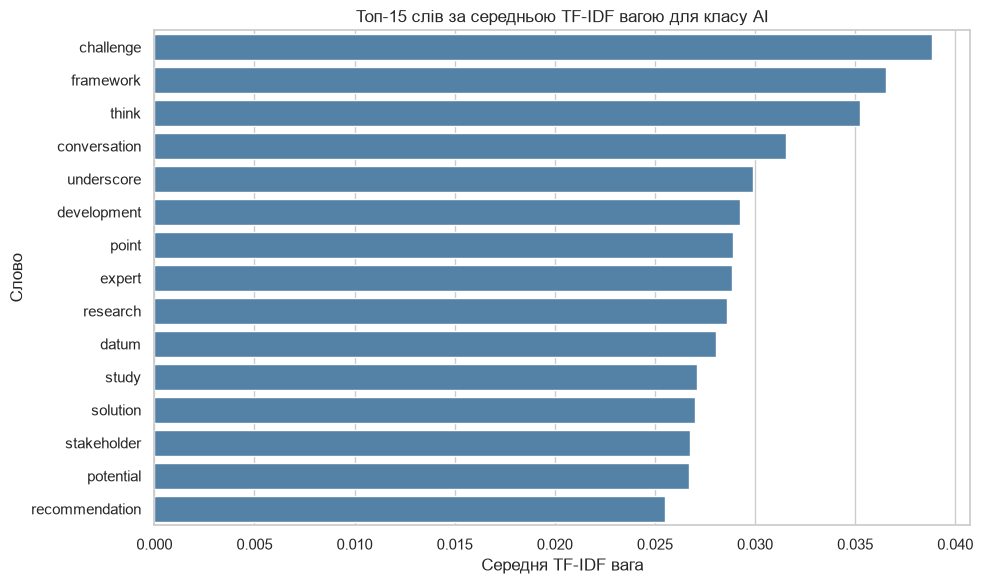

In [42]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_ai_words,
    x="AI TF-IDF",
    y="Word",
    color="steelblue"
)

plt.title(
    "Топ-15 слів за середньою TF-IDF вагою для класу AI"
)

plt.xlabel("Середня TF-IDF вага")
plt.ylabel("Слово")

plt.tight_layout()
plt.show()

**Висновок.**

Найбільші середні TF-IDF ваги отримали слова
challenge, framework, think, conversation
та underscore.

Серед характерних слів також присутня формальна,
аналітична та наукова лексика, зокрема development,
research, stakeholder, potential та recommendation.

Отримані результати свідчать про наявність
специфічних лексичних закономірностей у текстах
класу AI досліджуваного датасету.

### 8.2. Порівняння характерних слів класів Human та AI

Висока TF-IDF вага слова в одному класі не обов'язково
означає, що воно є характерним лише для цього класу.

Тому розрахуємо різницю між середніми TF-IDF вагами
кожного слова.

$$
\Delta(w)=TFIDF_{AI}(w)-TFIDF_{Human}(w)
$$

Додатні значення вказують на більшу характерність
слова для класу AI, а від'ємні — для класу Human.

In [43]:
word_weights["Difference"] = (
    word_weights["AI TF-IDF"] -
    word_weights["Human TF-IDF"]
)

top_ai_specific = word_weights.nlargest(
    15,
    "Difference"
)

top_human_specific = word_weights.nsmallest(
    15,
    "Difference"
)

print("Характерні слова класу AI:")

display(top_ai_specific.round(4))

print("Характерні слова класу Human:")

display(top_human_specific.round(4))

Характерні слова класу AI:


,Word,AI TF-IDF,Human TF-IDF,Difference
467,think,0.0352,0.0000,0.0352
484,underscore,0.0299,0.0000,0.0299
121,development,0.0293,0.0000,0.0293
159,expert,0.0288,0.0000,0.0288
175,framework,0.0365,0.0081,0.0285
432,solution,0.0270,0.0000,0.0270
438,stakeholder,0.0267,0.0000,0.0267
335,potential,0.0267,0.0000,0.0267
368,recommendation,0.0255,0.0000,0.0255
309,open,0.0252,0.0000,0.0252


Характерні слова класу Human:


,Word,AI TF-IDF,Human TF-IDF,Difference
25,argue,0.000,0.0381,-0.0381
184,get,0.000,0.0337,-0.0337
253,like,0.000,0.0316,-0.0316
236,investigation,0.000,0.0311,-0.0311
307,official,0.008,0.0380,-0.0300
485,understand,0.000,0.0275,-0.0275
19,announcement,0.000,0.0266,-0.0266
84,confirm,0.000,0.0266,-0.0266
100,critic,0.000,0.0266,-0.0266
256,line,0.000,0.0266,-0.0266


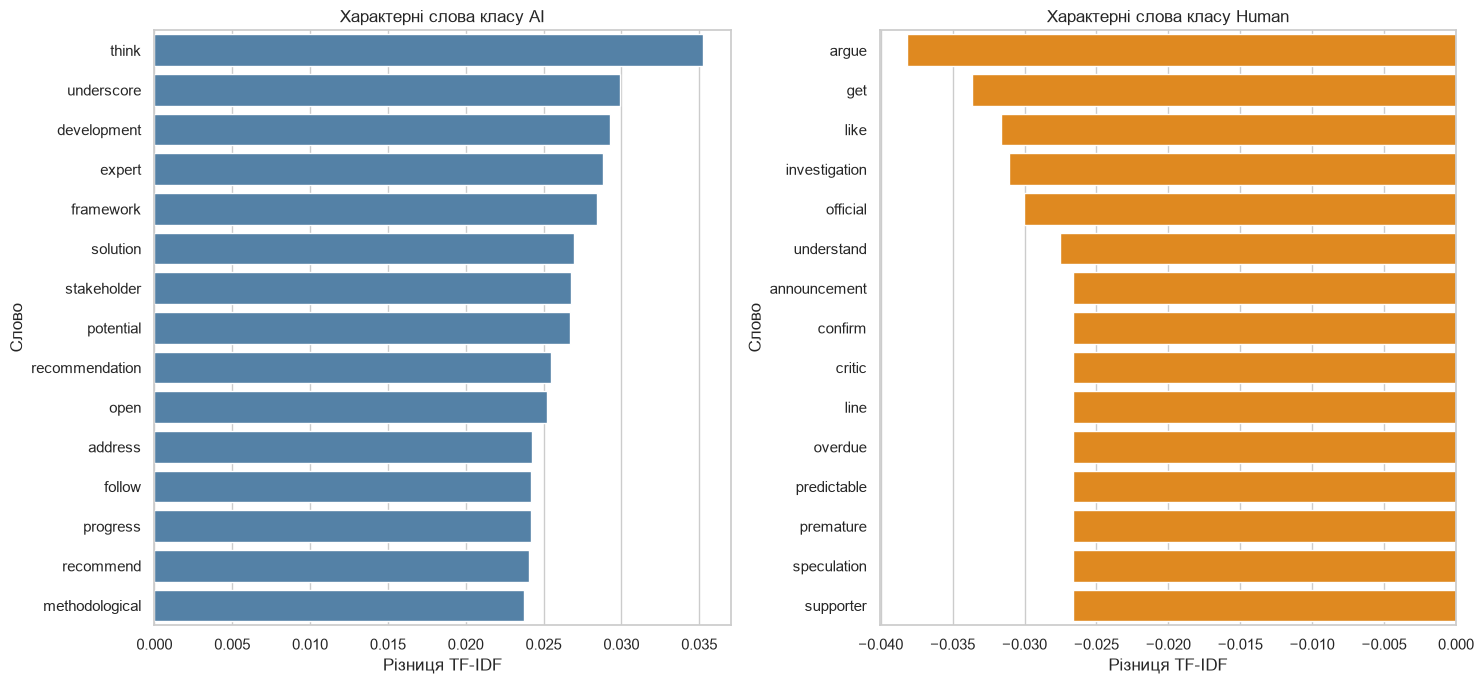

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

sns.barplot(
    data=top_ai_specific,
    x="Difference",
    y="Word",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Характерні слова класу AI")
axes[0].set_xlabel("Різниця TF-IDF")
axes[0].set_ylabel("Слово")

sns.barplot(
    data=top_human_specific,
    x="Difference",
    y="Word",
    color="darkorange",
    ax=axes[1]
)

axes[1].set_title("Характерні слова класу Human")
axes[1].set_xlabel("Різниця TF-IDF")
axes[1].set_ylabel("Слово")

plt.tight_layout()
plt.show()

**Висновок.**

Аналіз різниці середніх TF-IDF ваг дозволив виявити
виражені лексичні відмінності між класами.

Для класу AI найбільш характерними є слова think,
underscore, development, expert, framework,
solution та stakeholder.

Для класу Human характерними є слова argue, get,
like, investigation, official та understand.

Більшість виділених слів мають нульову середню
TF-IDF вагу в протилежному класі навчальної вибірки.

Це свідчить про наявність виражених лексичних
маркерів, які можуть сприяти високій точності
класифікації.

Однак ці слова не можна вважати універсальними
ознаками авторства штучного інтелекту або людини.

### 8.3. Аналіз характерних біграм

Окремі слова не завжди дозволяють повною мірою
визначити стилістичні особливості текстів.

Тому додатково дослідимо біграми — послідовності
з двох сусідніх токенів після попередньої обробки.

Для кожної біграми розрахуємо середню TF-IDF вагу
в обох класах та визначимо найбільш характерні
комбінації слів для текстів Human та AI.

Аналіз виконується на навчальній вибірці.

In [45]:
bigram_vectorizer = TfidfVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False,
    ngram_range=(2, 2),
    min_df=2
)

bigram_tfidf = bigram_vectorizer.fit_transform(
    train_texts
)

bigram_names = (
    bigram_vectorizer.get_feature_names_out()
)

ai_bigram_mean = np.asarray(
    bigram_tfidf[y_train_array == 1].mean(axis=0)
).ravel()

human_bigram_mean = np.asarray(
    bigram_tfidf[y_train_array == 0].mean(axis=0)
).ravel()

bigram_df = pd.DataFrame({
    "Bigram": bigram_names,
    "AI TF-IDF": ai_bigram_mean,
    "Human TF-IDF": human_bigram_mean
})

bigram_df["Difference"] = (
    bigram_df["AI TF-IDF"] -
    bigram_df["Human TF-IDF"]
)

top_ai_bigrams = bigram_df.nlargest(
    10,
    "Difference"
)

top_human_bigrams = bigram_df.nsmallest(
    10,
    "Difference"
)

print("Характерні біграми класу AI:")

display(top_ai_bigrams.round(4))

print("Характерні біграми класу Human:")

display(top_human_bigrams.round(4))

Характерні біграми класу AI:


,Bigram,AI TF-IDF,Human TF-IDF,Difference
27,approach thoughtfully,0.0219,0.0,0.0219
260,fascinating quickly,0.0219,0.0,0.0219
475,potential approach,0.0219,0.0,0.0219
504,quickly thing,0.0219,0.0,0.0219
656,thing move,0.0219,0.0,0.0219
661,thoughtfully thought,0.0219,0.0,0.0219
145,conversation polarization,0.0196,0.0,0.0196
188,discuss open,0.0196,0.0,0.0196
302,happy discuss,0.0196,0.0,0.0196
304,help happy,0.0196,0.0,0.0196


Характерні біграми класу Human:


,Bigram,AI TF-IDF,Human TF-IDF,Difference
22,announcement come,0.0,0.0259,-0.0259
34,argue premature,0.0,0.0259,-0.0259
109,come week,0.0,0.0259,-0.0259
154,critic argue,0.0,0.0259,-0.0259
193,divide predictable,0.0,0.0259,-0.0259
377,long overdue,0.0,0.0259,-0.0259
434,official confirm,0.0,0.0259,-0.0259
444,overdue public,0.0,0.0259,-0.0259
480,predictable line,0.0,0.0259,-0.0259
483,premature supporter,0.0,0.0259,-0.0259


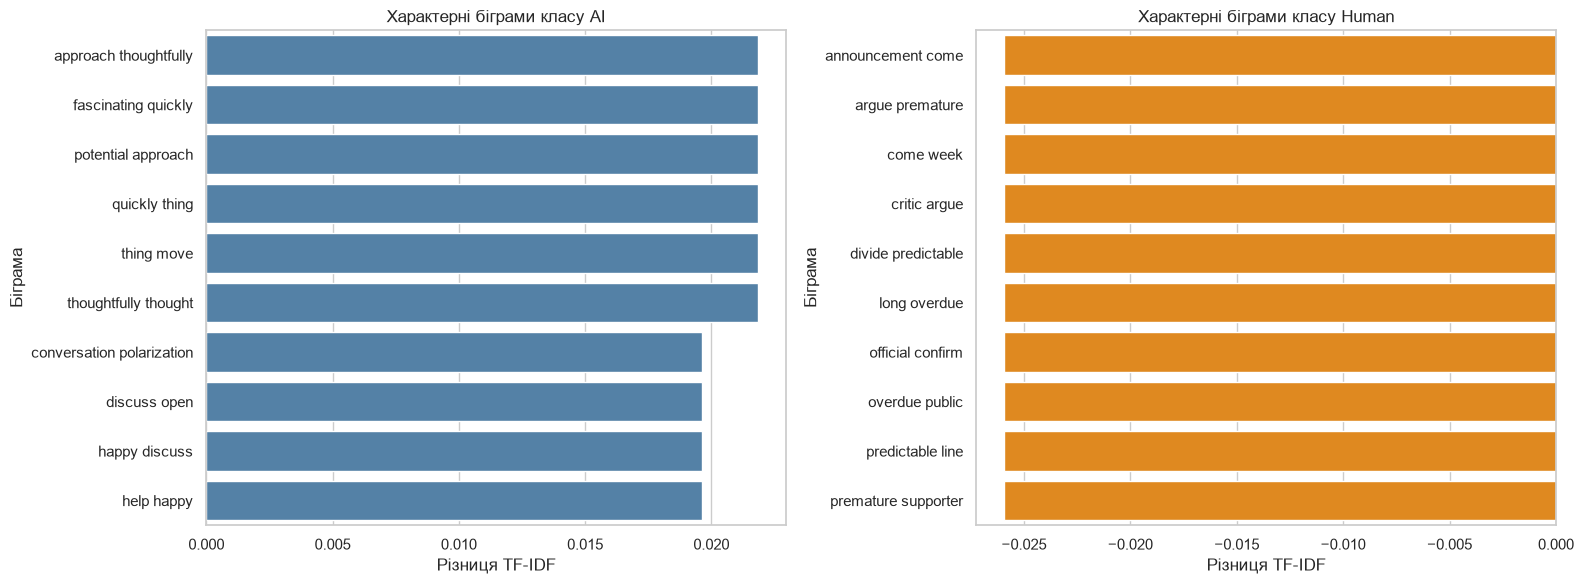

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=top_ai_bigrams,
    x="Difference",
    y="Bigram",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Характерні біграми класу AI")
axes[0].set_xlabel("Різниця TF-IDF")
axes[0].set_ylabel("Біграма")

sns.barplot(
    data=top_human_bigrams,
    x="Difference",
    y="Bigram",
    color="darkorange",
    ax=axes[1]
)

axes[1].set_title("Характерні біграми класу Human")
axes[1].set_xlabel("Різниця TF-IDF")
axes[1].set_ylabel("Біграма")

plt.tight_layout()
plt.show()

**Висновок.**

Для класу AI характерними є біграми approach thoughtfully,
potential approach, discuss open та happy discuss.

Для класу Human характерними є announcement come,
critic argue, long overdue та official confirm.

Однакові значення TF-IDF ваг для груп біграм
можуть свідчити про їх спільну появу
в повторюваних текстових шаблонах.

Таким чином, аналіз біграм додатково вказує
на можливу шаблонність досліджуваного датасету
та наявність специфічних мовних конструкцій
для кожного класу.

Необхідно враховувати, що біграми формуються після
видалення стоп-слів, тому відповідні слова можуть
не бути сусідніми в оригінальному тексті.

### 8.4. Дослідження шаблонності датасету

Для виявлення можливих особливостей формування
датасету дослідимо залежність між класами текстів,
їхніми тематичними категоріями та способами генерації.

Це дозволить визначити, чи можуть класифікатори
розпізнавати специфічні особливості шаблонів датасету,
а не універсальні ознаки текстів штучного інтелекту.

In [47]:
print("Розподіл класів за доменами:")

display(
    pd.crosstab(
        df_clean["domain"],
        df_clean["label"]
    )
)

print("Розподіл класів за способом генерації:")

display(
    pd.crosstab(
        df_clean["generation_method"],
        df_clean["label"]
    )
)

print("Розподіл класів за тематикою:")

display(
    pd.crosstab(
        df_clean["topic_hint"],
        df_clean["label"]
    )
)

Розподіл класів за доменами:


label,ai,human
domain,,
academic,130,116
news,126,180
social,131,185


Розподіл класів за способом генерації:


label,ai,human
generation_method,,
style_simulation,387,0
template+human_variation,0,481


Розподіл класів за тематикою:


label,ai,human
topic_hint,,
aging population challenges,15,17
algorithmic bias in hiring,13,16
antibiotic resistance,13,15
artificial intelligence regulation,15,16
autonomous vehicle safety,9,16
biodiversity loss,16,15
climate change adaptation strategies,13,16
cryptocurrency market volatility,12,16
cybersecurity threats to infrastructure,12,18


**Висновок.**

Аналіз розподілу документів показав, що обидва
класи представлені в усіх трьох доменах:
academic, news та social.

Також обидва класи представлені в усіх 30
тематичних категоріях.

Водночас виявлено повну відповідність між способом
генерації тексту та його класом.

Усі 387 документів класу AI мають спосіб генерації
style_simulation, а всі 481 документ класу Human —
template+human_variation.

Це свідчить про специфічний спосіб формування
датасету. Класифікатори можуть розпізнавати
особливості текстових шаблонів, а не універсальні
відмінності між текстами людини та штучного інтелекту.

### 8.5. Загальний висновок

У результаті аналізу TF-IDF ваг слів та біграм
виявлено виражені лексичні відмінності між
досліджуваними класами.

Ці відмінності разом із шаблонним характером
датасету можуть пояснювати високу точність
класифікаторів, незважаючи на слабку глобальну
кластерну роздільність ембеддингів.

Важливо зазначити, що стовпець generation_method
безпосередньо не використовувався для навчання
класифікаторів, тому його відповідність класам
сама по собі не є доказом витоку даних.

Отримана точність 100% характеризує якість
класифікації на конкретному датасеті, але не гарантує
аналогічних результатів на реальних текстах
з інших джерел.

## 9. Відповіді на дослідницькі питання

### 9.1. Як TF-IDF зважування впливає на геометрію простору ембеддингів та лінійну роздільність класів?

Для дослідження геометрії простору ембеддингів
було використано t-SNE, Silhouette Score,
відстані між центрами класів та коефіцієнт
роздільності.

| Показник | Mean Pooling | TF-IDF Pooling |
|---|---:|---:|
| Silhouette Score | 0,0369 | 0,0377 |
| Відстань між центрами | 3,2705 | 3,2626 |
| Коефіцієнт роздільності | 0,3489 | 0,3474 |
| Accuracy Logistic Regression | 99,43% | 99,43% |

Застосування TF-IDF зважування не призвело
до суттєвих змін геометрії простору ембеддингів.

Значення Silhouette Score залишилися близькими
до нуля, що свідчить про слабку глобальну
кластерну роздільність класів.

На графіках t-SNE також спостерігається значне
перекриття класів Human та AI.

Водночас висока точність Logistic Regression
свідчить про можливість ефективного розділення
класів лінійною межею в початковому 100-вимірному
просторі на досліджуваній вибірці.

Таким чином, TF-IDF зважування не забезпечило
помітного покращення лінійної роздільності класів.

### 9.2. Який класифікатор демонструє найкращі результати та як на них впливає TF-IDF зважування?

Для порівняння було використано три класифікатори:
SVM з RBF-ядром, Logistic Regression та KNN.

| Класифікатор | Accuracy Mean | Accuracy TF-IDF | Macro F1 Mean | Macro F1 TF-IDF |
|---|---:|---:|---:|---:|
| SVM (RBF) | 1,0000 | 1,0000 | 1,0000 | 1,0000 |
| Logistic Regression | 0,9943 | 0,9943 | 0,9942 | 0,9942 |
| KNN | 1,0000 | 1,0000 | 1,0000 | 1,0000 |

Найкращі результати продемонстрували SVM та KNN,
які правильно класифікували всі 174 тестові документи.

Logistic Regression допустила лише одну помилку.

Усі класифікатори отримали значення ROC-AUC,
рівне 1,0.

TF-IDF зважування не забезпечило покращення
жодної з досліджуваних метрик.

Це можна пояснити вираженими лексичними відмінностями
та шаблонним характером датасету, завдяки яким навіть
звичайне усереднення ембеддингів забезпечує високу
якість класифікації.

### 9.3. Чи спостерігається погіршення роботи KNN через прокляття розмірності?

Для дослідження концентрації відстаней було
розраховано середню попарну відстань, стандартне
відхилення та коефіцієнт варіації.

| Показник | Mean Pooling | TF-IDF Pooling |
|---|---:|---:|
| Середня відстань | 13,3684 | 13,3866 |
| Стандартне відхилення | 2,4246 | 2,3957 |
| Коефіцієнт варіації | 0,1814 | 0,1790 |
| Accuracy KNN | 100% | 100% |

Після застосування TF-IDF зважування коефіцієнт
варіації дещо зменшився, що свідчить про
незначне посилення концентрації відстаней.

Проте погіршення роботи KNN не спостерігається,
оскільки класифікатор забезпечив точність 100%
для обох методів формування ембеддингів.

Таким чином, у межах проведеного експерименту
негативного впливу прокляття розмірності
на якість KNN не виявлено.

Однак для детальнішого дослідження цього явища
необхідно провести додаткові експерименти
з різною розмірністю ембеддингів.

### 9.4. Які лінгвістичні маркери є характерними для текстів, згенерованих штучним інтелектом?

На основі аналізу середніх TF-IDF ваг було визначено
найбільш характерні слова та біграми для кожного класу.

| Тип маркерів | AI | Human |
|---|---|---|
| Слова | framework, underscore, development, expert, stakeholder, recommendation | argue, get, like, investigation, official, understand |
| Біграми | approach thoughtfully, potential approach, discuss open | critic argue, long overdue, official confirm |

Для текстів класу AI характерним є використання
формальної, аналітичної та наукової лексики.

У текстах класу Human спостерігаються як розмовні,
так і журналістські мовні конструкції.

Також встановлено, що всі тексти AI створені
методом style_simulation, а тексти Human —
методом template+human_variation.

Отже, виявлені лінгвістичні маркери можуть бути
наслідком особливостей формування датасету.

Їх не можна вважати універсальними ознаками
текстів, згенерованих штучним інтелектом.

### 9.5. Чи забезпечує TF-IDF зважування більшу компактність кластерів?

Для оцінювання компактності кластерів було використано
внутрішньокласове розсіювання, середні внутрішньокласові
та міжкласові відстані.

| Показник | Mean Pooling | TF-IDF Pooling |
|---|---:|---:|
| Розсіювання Human | 9,6933 | 9,6254 |
| Розсіювання AI | 9,0541 | 9,1571 |
| Human intra-class | 13,4389 | 13,3561 |
| AI intra-class | 12,6620 | 12,8076 |
| Inter-class | 13,6087 | 13,6374 |
| Inter/Intra | 1,0428 | 1,0425 |

Після застосування TF-IDF зважування компактність
класу Human дещо покращилася, тоді як розсіювання
класу AI збільшилося.

Відношення міжкласових до внутрішньокласових
відстаней практично не змінилося.

Таким чином, TF-IDF зважування не забезпечило
суттєвого покращення загальної компактності
кластерів та їхньої відокремленості.

## 10. Узагальнення результатів дослідження

### 10.1. Визначення найкращих моделей

Для підбиття підсумків експерименту визначимо
всі комбінації методів формування ембеддингів
та класифікаторів, які отримали максимальне
значення метрики Macro F1.

In [48]:
best_results = results_df[
    results_df["Macro F1"] ==
    results_df["Macro F1"].max()
]

print("Найкращі комбінації:")

display(best_results.round(4))

Найкращі комбінації:


,Representation,Classifier,Accuracy,Balanced Accuracy,Macro F1,ROC-AUC
0,Mean Pooling,SVM (RBF),1.0,1.0,1.0,1.0
2,Mean Pooling,KNN,1.0,1.0,1.0,1.0
3,TF-IDF Pooling,SVM (RBF),1.0,1.0,1.0,1.0
5,TF-IDF Pooling,KNN,1.0,1.0,1.0,1.0


**Висновок.**

Найкращі результати отримано для чотирьох комбінацій:

- Mean Pooling + SVM;
- Mean Pooling + KNN;
- TF-IDF Pooling + SVM;
- TF-IDF Pooling + KNN.

Усі зазначені комбінації отримали максимальні
значення досліджуваних метрик.

За отриманими результатами неможливо визначити
однозначно найкращу комбінацію.

### 10.2. Порівняння середньої ефективності методів формування ембеддингів

Для загального порівняння методів Mean Pooling
та TF-IDF Pooling розрахуємо середні значення
метрик за всіма досліджуваними класифікаторами.

In [49]:
summary_results = results_df.groupby(
    "Representation"
)[
    [
        "Accuracy",
        "Balanced Accuracy",
        "Macro F1",
        "ROC-AUC"
    ]
].mean()

display(summary_results.round(4))

,Accuracy,Balanced Accuracy,Macro F1,ROC-AUC
Representation,,,,
Mean Pooling,0.9981,0.9983,0.9981,1.0
TF-IDF Pooling,0.9981,0.9983,0.9981,1.0


**Висновок.**

Середні значення метрик класифікації для Mean Pooling
та TF-IDF Pooling є однаковими.

Середня Accuracy становить приблизно 99,81%,
а середня ROC-AUC дорівнює 1,0.

Таким чином, у межах проведеного експерименту
TF-IDF зважування не забезпечило переваги
над звичайним усередненням ембеддингів.

Mean Pooling є простішим методом формування
векторних представлень та забезпечує аналогічну
якість класифікації на досліджуваному датасеті.

### 10.3. Збереження результатів експерименту

Для забезпечення можливості подальшого аналізу
та повторного використання результатів збережемо:

- метрики класифікаторів;
- геометричні характеристики ембеддингів;
- результати аналізу відстаней;
- результати дослідження концентрації відстаней;
- TF-IDF ваги слів та біграм;
- навчену модель FastText.

In [50]:
from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

results_df.to_csv(
    results_dir / "classification_results.csv",
    index=False
)

geometry_df.to_csv(
    results_dir / "geometry_results.csv",
    index=False
)

distance_df.to_csv(
    results_dir / "distance_results.csv",
    index=False
)

concentration_df.to_csv(
    results_dir / "concentration_results.csv",
    index=False
)

word_weights.to_csv(
    results_dir / "word_weights.csv",
    index=False
)

bigram_df.to_csv(
    results_dir / "bigram_weights.csv",
    index=False
)

summary_results.to_csv(
    results_dir / "summary_results.csv"
)

fasttext_model.save(
    str(results_dir / "fasttext.model")
)

print("Результати успішно збережено.")

for file in results_dir.iterdir():
    print(file.name)

Результати успішно збережено.
bigram_weights.csv
classification_results.csv
concentration_results.csv
distance_results.csv
fasttext.model
fasttext.model.wv.vectors_ngrams.npy
geometry_results.csv
summary_results.csv
word_weights.csv


**Висновок.**

Результати експерименту збережено у форматі CSV,
а навчену модель FastText — у вигляді окремого
артефакту.

Збережені результати можуть використовуватися
для подальшого аналізу, порівняння моделей
та повторного використання навчених ембеддингів.

## 11. Загальний висновок

У ході виконання лабораторної роботи було досліджено
ефективність використання векторних представлень
текстових документів на основі моделі FastText
для розв'язання задачі бінарної класифікації текстів,
написаних людиною та згенерованих штучним інтелектом.

Було проведено первинний аналіз даних, досліджено
баланс класів, характеристики довжини текстів,
наявність дублікатів та особливості формування
датасету.

У результаті очищення та попередньої обробки
початковий набір із 2000 документів було скорочено
до 868 унікальних оброблених документів.

За допомогою бібліотеки spaCy реалізовано токенізацію,
лематизацію, видалення стоп-слів та приведення
тексту до нижнього регістру.

На навчальній вибірці навчено модель FastText
за архітектурою Skip-gram із розмірністю векторних
представлень 100.

Реалізовано та порівняно два методи формування
ембеддингів документів: звичайне усереднення
векторів слів (Mean Pooling) та зважене усереднення
на основі TF-IDF (TF-IDF Pooling).

Для класифікації використано алгоритми SVM
з RBF-ядром, Logistic Regression та KNN.

Найкращі результати продемонстрували SVM та KNN,
які досягли точності 100% для обох методів
формування ембеддингів.

Точність Logistic Regression становила 99,43%.
Усі класифікатори отримали значення ROC-AUC,
рівне 1,0.

Застосування TF-IDF зважування не забезпечило
покращення метрик класифікації, загальної
компактності кластерів або їхньої роздільності.

Аналіз геометрії ембеддингів за допомогою t-SNE,
Silhouette Score та попарних відстаней показав
слабку глобальну кластерну роздільність класів,
незважаючи на високу ефективність класифікаторів.

Дослідження лінгвістичних маркерів дозволило
виявити виражені лексичні відмінності між класами.

Додаткова перевірка показала відсутність точних
дублікатів між навчальною та тестовою вибірками,
проте для 31,61% тестових документів косинусна
подібність до найближчого навчального документа
перевищувала 0,9.

Отримані результати свідчать про те, що висока
точність класифікації може бути пов'язана
із шаблонним характером датасету.

Тому для оцінювання узагальнювальної здатності
моделей доцільно використовувати більш різноманітні
набори даних, розділення за групами схожих шаблонів
та незалежні тестові вибірки.

Таким чином, мету лабораторної роботи досягнуто,
реалізовано та експериментально порівняно методи
формування векторних представлень текстів,
досліджено ефективність класифікаторів, геометричні
характеристики ембеддингів та вплив TF-IDF
зважування на якість класифікації.